# Exploring data: distributions, charts and relationships

After this block you can describe a variable in a way that fits its type (a sensible centre, spread, shape and frequency table), choose and design a chart that answers one question for every reader, including readers with a colour vision deficiency, and measure how strongly two numeric variables move together without being fooled by outliers or by a third variable. The block serves two learning outcomes of the session: describing data by variable type with descriptive statistics and well-designed charts, and computing and interpreting correlations as the starting point for regression.

All examples use the Inside Airbnb listings of Berlin (snapshot of 26 June 2026, CC BY 4.0), downloaded once as `airbnb-v1.zip` from the course drive and unzipped into `case-study/data/` (see [case-study/README.md](../../../case-study/README.md)). The listings come from public pages; host names and texts have been removed, and we report only aggregates.

## Overview

| Section | What it covers |
|---|---|
| Setup | the listings and the short-stay subset |
| Describing data by variable type | variable types, histograms and box plots, bin width, discrete and categorical variables, comparing groups, kernel density estimates and the ECDF, strip, box, violin and point plots by category, centre and spread, robust summaries, frequency tables, validating a variable |
| Choosing and designing charts | choosing a chart for the question, perception and proportional ink, matplotlib (Figure, Axes, interfaces, labels, annotation, styling, scales, layouts), colour palettes, colour maps and accessibility, seaborn small multiples, interactive charts with Plotly Express and their styling, critiquing a chart |
| Relationships between numeric variables | scatter plots, binned percentiles, Pearson and Spearman correlation, r², covariance and correlation matrices, testing a correlation, confounding and Simpson's paradox |
| Worked example | what a short-stay night costs by room type, district and number of guests |
| Check your understanding, Exercises, Debrief | five multiple-choice questions, nine exercises in pairs, what to compare afterwards |

## Setup

The first cell moves the working directory to the repository root, so that the paths `case-study/data/...` work wherever Jupyter was started.

In [1]:
# Run the code from the repository root, where the case-study paths start.
import os
from pathlib import Path

os.chdir(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "case-study").is_dir()))

Next we load the listings and keep a second table `short_stay_listings`. [Session 4, block 2](../../04-data-quality/workbooks/02-lecture-outliers-transformations-and-cleaning-pipeline.ipynb) showed that listings with a minimum stay of 28 nights or more fill the price field differently, so their prices are not comparable with short stays. `df[mask]` keeps the rows where a Boolean mask is `True`; `&` combines two masks; `.copy()` makes `short_stay_listings` an independent table we may add columns to. `plt.rcParams` sets defaults for every chart of the notebook (here: no top and right frame lines).

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy import stats

listings = pd.read_parquet("case-study/data/airbnb/listings.parquet")
short_stay_listings = listings[listings["price"].notna() & listings["minimum_nights"].lt(28)].copy()
short_stay_listings["log_price"] = np.log(short_stay_listings["price"])
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})
print(f"{len(listings):,} listings, {len(short_stay_listings):,} short-stay listings with a price")

10,221 listings, 5,302 short-stay listings with a price


## Describing data by variable type

Exploratory data analysis (EDA) is the first look at a dataset before any test or model: which values occur, how often, and what looks wrong. We describe one variable at a time, and the type of the variable decides which summaries and charts make sense.

### Variable types

A **variable** is one column of a table: one property measured for every observation (here, every listing). Its **type** decides which arithmetic makes sense. Think of a football shirt: number 10 is not "twice" number 5. Some numbers are codes, not quantities.

| Type | Meaning | Example in the listings | Sensible summaries | Typical chart |
|---|---|---|---|---|
| **Nominal** | categories without order | `room_type`, `district`, `host_is_superhost` | counts, shares, mode | sorted bar chart |
| **Ordinal** | categories with an order but no fixed distance | the 1 to 5 stars a single guest gives | counts, shares, median | bar chart in order |
| **Count** (discrete numeric) | whole numbers from counting | `accommodates`, `minimum_nights`, `number_of_reviews` | median, quantiles, share of zeros | bar chart of counts |
| **Continuous** numeric | measurements | `price` (EUR per night), `latitude` | mean, median, SD, IQR | histogram, box plot |
| **Date/time** | a point in time | `last_review` | range, counts per period | line chart over time |

The listing `id` looks like a number but is a code: its mean means nothing. Postal codes are the classic trap: read as integers, `01067` (Dresden) becomes `1067`. For ordinal data, the mean of the stars 1, 5 and 5 is 3.67, which assumes that the step from 1 to 2 stars is as large as the step from 4 to 5. The median (5 stars) and the share of 5-star ratings (two of three) need no such assumption. The average `review_scores_rating` of a listing is a mean of many such stars; treating it as continuous is a convention that works reasonably well, but it is bounded at 5 and crowded near the top.

Next we ask pandas how it stores some columns. `df.dtypes` shows the storage type and `Series.nunique()` the number of distinct values.

**Predict.** Which storage type will the listing `id` have?

In [3]:
cols = ["id", "room_type", "district", "accommodates", "price", "last_review"]
print(listings[cols].dtypes)
print("districts:", listings["district"].nunique(), "| neighbourhoods:", listings["neighbourhood"].nunique())

id                       int64
room_type                  str
district                   str
accommodates             int64
price                  float64
last_review     datetime64[us]
dtype: object
districts: 12 | neighbourhoods: 137


The storage type is not the measurement level. `id` is stored as an integer, yet it is a nominal code; `describe()` would happily report its mean. Decide the type yourself, from what the column means, and convert codes to text or `category` when you load them (`dtype={"zip": "string"}` in `pd.read_csv`).

### Distributions: histograms and box plots

The **distribution** of a variable says which values occur and how often. We describe it by its **centre** (a typical value), its **spread** (how far values scatter) and its **shape**: symmetric or **skewed** (a long tail on one side), one peak (unimodal) or several (multimodal), gaps, spikes at round numbers.

A **histogram** cuts the value range into intervals (bins) and draws one bar per bin, its height the number of observations in the bin. A **box plot** draws the quartiles as a box, the median as a line inside it, whiskers to the most extreme points within 1.5 IQR of the box, and single points beyond the whiskers as dots. Prices are skewed to the right: most nights cost between €77 and €334, a few several thousand euros. On a linear axis the tail squeezes the bulk into the first bars. On a **logarithmic axis** equal distances stand for equal ratios (€10, €100, €1,000), and the shape becomes readable.

![Histogram of the short-stay price per night on a linear and a logarithmic axis, with mean and median marked](../figures/skewed-distribution.png)

Next we draw the histogram on a log axis and one box per room type. `sns.histplot(data, x=..., log_scale=True)` draws a histogram with logarithmic bins; `sns.boxplot(data, x=..., y=...)` draws one box per category; `Series.skew()` measures asymmetry (0 means symmetric, positive means a long right tail).

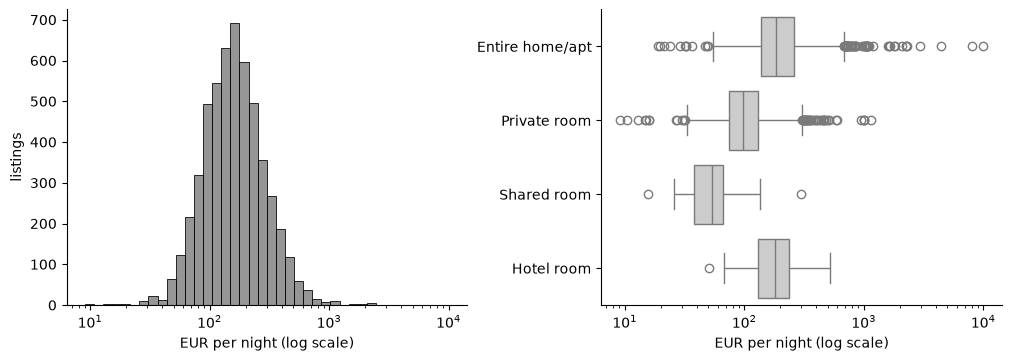

skewness: 23.2
below 20 EUR: 10 | above 1,000 EUR: 24


In [4]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
sns.histplot(short_stay_listings, x="price", log_scale=True, bins=40, color="0.45", ax=left)
left.set(xlabel="EUR per night (log scale)", ylabel="listings")
sns.boxplot(short_stay_listings, x="price", y="room_type", log_scale=True, color="0.8", ax=right)
right.set(xlabel="EUR per night (log scale)", ylabel="")
plt.show()
print("skewness:", round(short_stay_listings["price"].skew(), 1))
print("below 20 EUR:", (short_stay_listings["price"] < 20).sum(), "| above 1,000 EUR:", (short_stay_listings["price"] > 1000).sum())

**What do you see?** Which room type's box lies furthest to the right, and how far does the tail of the histogram reach?

The skewness is far above 0: a long right tail. On the log axis the bulk looks roughly symmetric, and the boxes show the first explanation of the spread: entire homes cost more than private rooms. The few listings below €20 and above €1,000 deserve a look at the raw rows before we trust any summary (see *Validating a variable* at the end of this section).

> **Note.** Very different datasets can share the same mean and standard deviation. Anscombe's quartet (1973) and the Datasaurus Dozen (Matejka & Fitzmaurice, 2017) were built to show this. Plot before you summarise.

#### Choosing the bin width

*Adapted from [Visualizing distributions of data](https://seaborn.pydata.org/tutorial/distributions.html) (Michael Waskom, BSD-3-Clause), applied to the Berlin listings.*

The **bin width** is the width of the intervals a histogram counts in. The size of the bins is an important parameter, and using the wrong bin size can mislead by obscuring important features of the data or by creating apparent features out of random variability. By default, `histplot` chooses a bin size based on the variance of the data and the number of observations. Do not rely on such automatic choices: check that your impression of the distribution holds across different bin sizes. `binwidth=` sets the width of each bin, `bins=` the number of bins.

Next we draw the log price with three bin widths side by side.

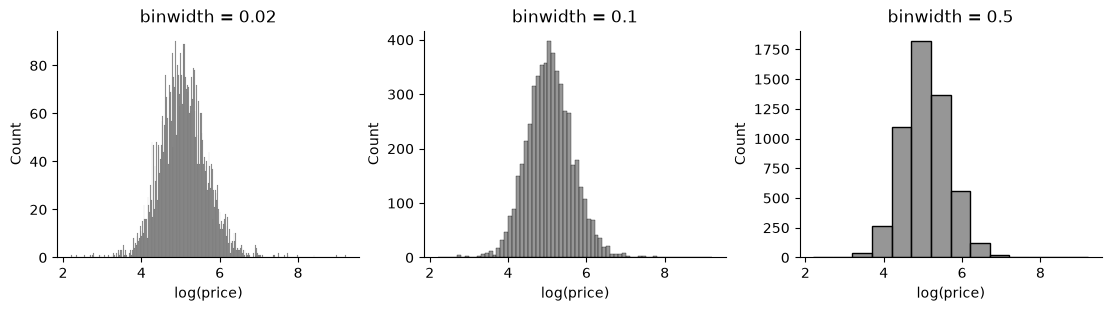

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3), layout="constrained", sharey=False)
for ax, width in zip(axes, [0.02, 0.1, 0.5]):
    sns.histplot(short_stay_listings, x="log_price", binwidth=width, color="0.45", ax=ax)
    ax.set(title=f"binwidth = {width}", xlabel="log(price)")
plt.show()

**What do you see?** In which panel do spikes at round prices appear, and in which does the shape of the distribution disappear?

Too narrow and the histogram shows noise (and spikes at round prices such as €100 and €150, which are real, as hosts like round numbers); too wide and it hides the shape.

#### Discrete and categorical variables

When a variable takes only a few integer values, the default bins can create awkward gaps. `discrete=True` puts one bar on each value, centred on it. For a categorical variable the same logic gives a bar per category; `shrink=.8` narrows the bars to emphasise that the axis is categorical.

Next we draw the number of guests with `discrete=True` and the room types with `shrink`.

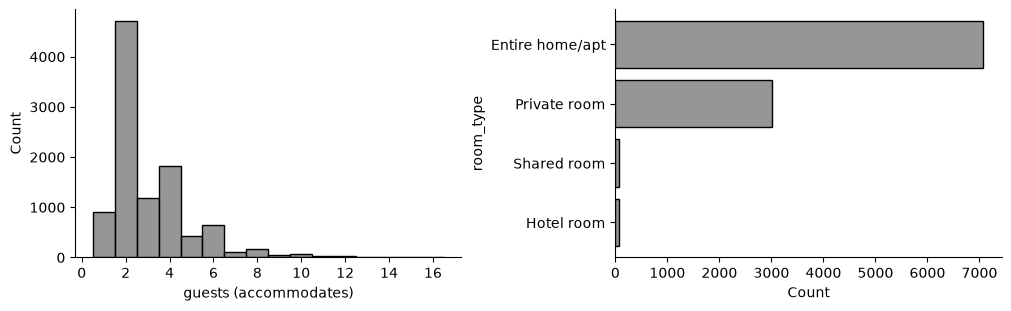

In [6]:
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3), layout="constrained")
sns.histplot(listings, x="accommodates", discrete=True, color="0.45", ax=left)
sns.histplot(listings, y="room_type", shrink=0.8, color="0.45", ax=right)
left.set(xlabel="guests (accommodates)")
plt.show()

#### Comparing distributions across groups

Once you understand the distribution of one variable, the next question is whether it differs across groups. `hue=` draws one histogram per group. Layered bars are hard to read; `element="step"` draws outlines, `multiple="stack"` stacks them (the outline then shows the whole distribution, but the shape of each group is hard to judge), and `multiple="dodge"` puts bars side by side. When groups differ in size, compare **shares** instead of counts: `stat="density"` with `common_norm=False` normalises each group separately, and `stat="probability"` makes the bar heights sum to 1.

Next we compare the price of entire homes and private rooms with step outlines, each group normalised on its own.

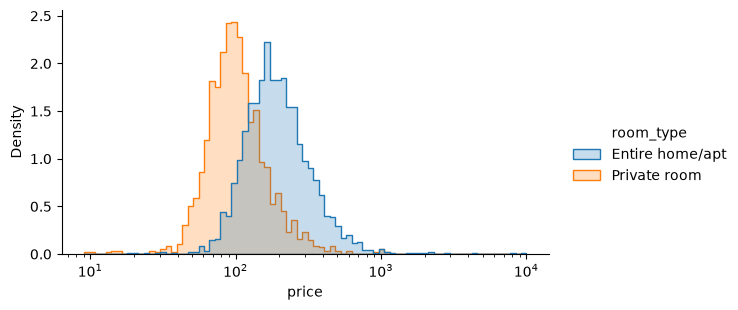

In [7]:
two = short_stay_listings[short_stay_listings["room_type"].isin(["Entire home/apt", "Private room"])]
sns.displot(two, x="price", hue="room_type", log_scale=True, element="step",
            stat="density", common_norm=False, height=3.2, aspect=1.8)
plt.show()

### Kernel density estimates and the ECDF

*Adapted from [Visualizing distributions of data](https://seaborn.pydata.org/tutorial/distributions.html) (Michael Waskom, BSD-3-Clause), applied to the Berlin listings.*

#### Kernel density estimates

A histogram approximates the underlying density by binning and counting. **Kernel density estimation (KDE)** smooths each observation with a small Gaussian bump instead and adds the bumps up, giving a continuous curve. As with bin size, the **bandwidth** decides how faithful the curve is: an over-smoothed estimate erases real features, an under-smoothed one shows noise. `bw_adjust` scales the default bandwidth.

Next we draw the log-price density for three bandwidths.

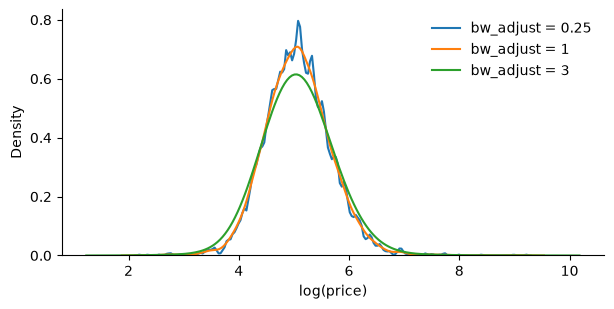

In [8]:
fig, ax = plt.subplots(figsize=(7, 3.2))
for adjust in [0.25, 1, 3]:
    sns.kdeplot(short_stay_listings, x="log_price", bw_adjust=adjust, label=f"bw_adjust = {adjust}", ax=ax)
ax.legend(frameon=False)
ax.set(xlabel="log(price)")
plt.show()

KDE has pitfalls. It assumes the distribution is smooth and unbounded. For a quantity that cannot be negative, the curve spills below zero; `cut=0` stops drawing at the data's extremes, but the estimate is still artificially low near the bound. And a KDE always shows a smooth curve, even when the data are not smooth: a variable with spikes at a few values (such as `availability_365`, with many listings at 0) looks like a gentle hill. `kde=True` inside `histplot` overlays the curve on the histogram, a useful compromise.

#### The empirical cumulative distribution function (ECDF)

The **empirical cumulative distribution function (ECDF)** draws, for every value x, the share of observations at or below x. It has no bin width or bandwidth to choose, it shows every data point, and because each curve only rises, several groups compare well on one chart. Its downside: the shape (for example two peaks) shows only as changes of slope. Reading it is easy once practised: the median is where the curve crosses 0.5.

Next we compare the ECDF of the price for the four room types. `sns.ecdfplot(data, x=..., hue=...)` draws one curve per group.

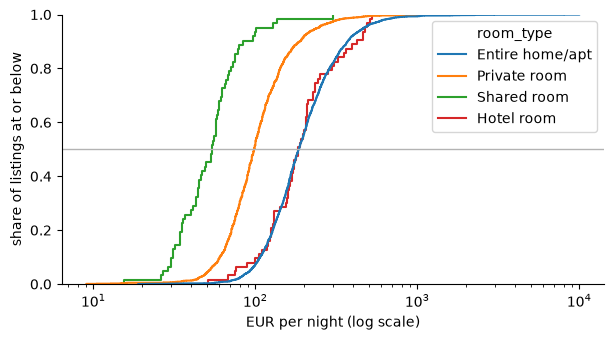

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.ecdfplot(short_stay_listings, x="price", hue="room_type", log_scale=True, ax=ax)
ax.axhline(0.5, color="0.7", linewidth=1)
ax.set(xlabel="EUR per night (log scale)", ylabel="share of listings at or below")
plt.show()

Where each curve crosses the grey line at 0.5 is the median of that room type. Two-variable versions exist too: `sns.displot(..., x=..., y=...)` draws a bivariate histogram, `kind="kde"` contour lines, and `sns.jointplot` adds the two marginal distributions; the section on scatter plots below uses a hexbin plot for the same purpose.

> 📖 **Read more:** [extras/03-seaborn-distributions.ipynb](extras/03-seaborn-distributions.ipynb) (seaborn documentation): the full tutorial with all options for histograms, KDE, ECDF and bivariate distributions, on the penguins and tips datasets.

### Strip, box, violin and point plots by category

*Adapted from [Visualizing categorical data](https://seaborn.pydata.org/tutorial/categorical.html) (Michael Waskom, BSD-3-Clause), applied to the Berlin listings.*

When one variable is categorical, seaborn offers three families of plots through the figure-level function `sns.catplot(..., kind=...)`:

- **categorical scatter plots** (`kind="strip"`, the default, or `"swarm"`): every observation, spread out along the category axis by random jitter (strip) or by an algorithm that avoids overlap (swarm, only for small datasets);
- **distribution plots** (`"box"`, `"violin"`, `"boxen"`): summaries of the distribution in each category;
- **estimate plots** (`"bar"`, `"point"`, `"count"`): one estimate (by default the mean) per category, with a confidence interval.

#### Strip plot with a box plot on top

Next we compare the price distributions of the six largest districts as a strip plot with a box plot on top. `order=` fixes the category order; `native_scale` keeps numbers on a numeric axis; `ax=` draws several plots into one Axes.

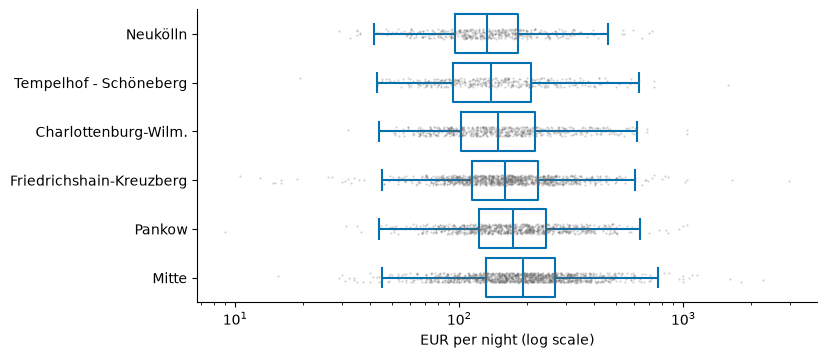

In [10]:
top6 = short_stay_listings["district"].value_counts().index[:6]
sub = short_stay_listings[short_stay_listings["district"].isin(top6)]
order = sub.groupby("district")["price"].median().sort_values().index
fig, ax = plt.subplots(figsize=(8, 3.8))
sns.stripplot(sub, x="price", y="district", order=order, log_scale=True, size=1.5, alpha=0.3, color="0.4", ax=ax)
sns.boxplot(sub, x="price", y="district", order=order, log_scale=True, showfliers=False, fill=False, color="#0072B2", ax=ax)
ax.set(xlabel="EUR per night (log scale)", ylabel="")
plt.show()

#### Violin and boxen plots

A **violin plot** combines a box plot with a KDE drawn on both sides, giving a richer picture of the shape but adding the KDE's tuning parameters (`bw_adjust`, `cut`). A **boxen plot** draws more quantiles than a box plot and suits large datasets. Next we draw the price by room type as violins, with `inner="quart"` drawing the quartiles inside.

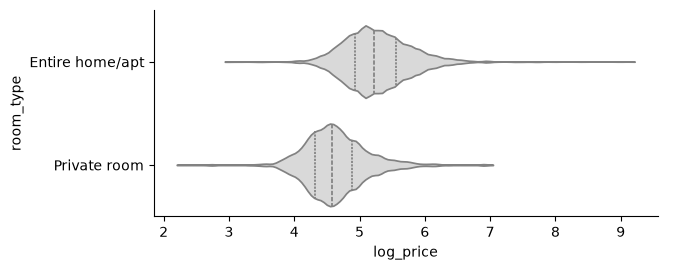

In [11]:
sns.catplot(two, x="log_price", y="room_type", kind="violin", inner="quart", cut=0,
            bw_adjust=0.5, height=2.8, aspect=2.4, color="0.85")
plt.show()

#### Estimate plots: bar and point plots

Estimate plots show one number per category. `kind="bar"` draws the mean with a 95 % confidence interval obtained by bootstrapping (resampling the data many times); `errorbar=("pi", 50)` shows the middle 50 % of the data instead; `estimator="median"` changes the statistic. A **point plot** draws the same estimate as a dot and connects the dots of one `hue` level, which makes changes of slope easy to see; vary marker and line style together with colour so the plot survives greyscale printing.

Next we draw the median price per number of guests for entire homes and private rooms as a point plot.

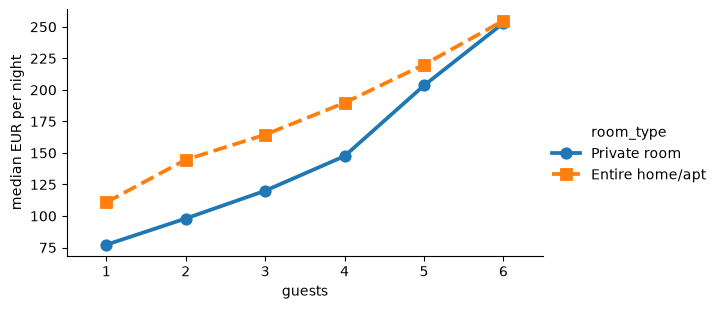

In [12]:
small = two[two["accommodates"].between(1, 6)]
g = sns.catplot(small, x="accommodates", y="price", hue="room_type", kind="point", estimator="median",
                errorbar=None, markers=["o", "s"], linestyles=["-", "--"], height=3.2, aspect=1.8)
g.set_axis_labels("guests", "median EUR per night")
plt.show()

> 📖 **Read more:** [extras/04-seaborn-categorical.ipynb](extras/04-seaborn-categorical.ipynb) (seaborn documentation): every categorical plot kind with its options, including swarm plots, split violins and faceting.

### Centre and spread

- The **mean** is the sum divided by the count, the balance point of the data. Every value pulls on it, so a long tail drags it towards the tail.
- The **median** is the middle value after sorting; half of the data lie below it.
- The **mode** is the most frequent value; it is the only centre for nominal data.
- The **variance** is the average squared distance from the mean; the **standard deviation (SD)** is its square root, roughly the typical distance from the mean. Squaring makes large deviations dominate it.
- The **quartiles** Q1 and Q3 cut off the lowest and the highest quarter. The **interquartile range** IQR = Q3 − Q1 is the width of the middle half.

A small example: five nightly prices of €80, €120, €150, €180 and €970 have a mean of €1,500 / 5 = €300, but four of the five cost less than €181. The median is €150. Drop the €970 listing and the mean falls to €132.50, while the median moves only to €135.

**Predict.** For the short-stay prices, which is larger, the mean or the median?

Next we compute both, the SD and the quartiles. `Series.agg([...])` applies several summaries at once; `Series.quantile([...])` returns the requested quantiles.

In [13]:
print(short_stay_listings["price"].agg(["mean", "median", "std"]).round(1).to_dict())
q1, q3 = short_stay_listings["price"].quantile([0.25, 0.75])
print("Q1:", q1, "| Q3:", q3, "| IQR:", q3 - q1)

{'mean': 195.6, 'median': 157.5, 'std': 235.2}
Q1: 107.5 | Q3: 230.5 | IQR: 123.0


The mean lies well above the median: the tail pulls it up. One centre is also not enough when a variable has two peaks. Next we look at three count variables with `describe()`, which prints count, mean, SD, min, quartiles and max; `.loc[rows]` keeps the rows we want to compare.

In [14]:
counts = listings[["accommodates", "minimum_nights", "number_of_reviews"]]
print(counts.describe().round(1).loc[["mean", "50%", "std", "max"]])
print("share with a minimum stay of exactly 92 nights:", round((listings["minimum_nights"] == 92).mean(), 3))

      accommodates  minimum_nights  number_of_reviews
mean           3.1            34.6               52.1
50%            2.0             3.0               11.0
std            2.0            52.5              105.7
max           16.0          1125.0             1925.0
share with a minimum stay of exactly 92 nights: 0.291


The minimum stay has a median of 3 nights and a far higher mean, because the listings form two clusters: short stays of a few nights and a large group that requires exactly 92 nights (Session 4). "Mean ± 2 SD" would even include negative stays. No single number describes a variable with two peaks: describe the clusters in words and shares.

### Robust summaries

A summary is **robust** if a few extreme values cannot move it far. The **breakdown point** is the share of observations that can be replaced by arbitrary values before the summary becomes arbitrary: 0 % for the mean (one huge value is enough), 50 % for the median. Robust alternatives:

- the **median** instead of the mean;
- the **IQR** or the **median absolute deviation (MAD)**, the median of |x − median|, instead of the SD;
- the **trimmed mean**, which drops a fixed share at each end before averaging (as sports judges drop the highest and lowest score);
- **quantiles** such as the 10th and 90th percentile, which describe the tails directly.

Next we compare the classical and the robust summaries of the price. `stats.trim_mean(x, 0.1)` cuts 10 % at each end; `stats.median_abs_deviation(x)` computes the MAD.

In [15]:
price = short_stay_listings["price"]
print("mean:", round(price.mean(), 1), "| 10 % trimmed mean:", round(stats.trim_mean(price, 0.1), 1),
      "| median:", price.median())
print("SD:", round(price.std(), 1), "| MAD:", stats.median_abs_deviation(price))
print(price.quantile([0.1, 0.5, 0.9, 0.99]).round(0).to_dict())

mean: 195.6 | 10 % trimmed mean: 169.1 | median: 157.5
SD: 235.2 | MAD: 57.084999999999994
{0.1: 77.0, 0.5: 158.0, 0.9: 334.0, 0.99: 703.0}


In plain words: "A short-stay night in Berlin costs €157.50 at the median; one listing in ten costs less than €77, one in ten more than €334." Three quantiles describe the price better than mean and SD, which a few extreme prices pull up.

Ratings show the opposite problem: they are crowded at the top. Next we describe the average rating with the median, the MAD and two shares.

In [16]:
rating = listings["review_scores_rating"].dropna()
print("median:", rating.median(), "| MAD:", round(stats.median_abs_deviation(rating), 2))
print("share with a perfect 5.0:", round((rating == 5).mean(), 3), "| share below 4:", round((rating < 4).mean(), 3))

median: 4.86 | MAD: 0.14
share with a perfect 5.0: 0.267 | share below 4: 0.016


A quarter of rated listings have a perfect 5.0 and very few are below 4, so a listing rated 4.5 is below the typical listing. Keep this in mind whenever you compare ratings.

> **Note.** A small MAD does not always mean little spread. If more than half of the values are identical, the MAD is 0. The minimum stay has a small MAD although a large share of listings require 92 nights. Always look at the share of the most common values as well.

> 📖 **Read more:** [extras/01-exploratory-data-analysis.ipynb](extras/01-exploratory-data-analysis.ipynb) (Think Stats, chapter 1): a first exploration of a survey dataset, from reading the file to validation and summary statistics. [extras/02-descriptive-statistics-and-t-test.ipynb](extras/02-descriptive-statistics-and-t-test.ipynb) (Microsoft Data Science for Beginners): mean, variance, box plots by group and the normal distribution on the heights and weights of baseball players.

### Frequency tables

For nominal and ordinal variables the summary is a **frequency table**: the count and the share (relative frequency) of each category. A **cross-tabulation** counts combinations of two categorical variables; block 2 tests such tables with the chi-square test. Shares make groups of different size comparable; counts show whether a share rests on 10 or 10,000 listings. Report both: a share of 100 % shared rooms means little if a district has one shared room.

Next we build the frequency table of the room type. `value_counts()` counts each category; with `normalize=True` it returns shares.

In [17]:
room = pd.DataFrame({"n": listings["room_type"].value_counts(),
                     "share": listings["room_type"].value_counts(normalize=True).round(3)})
room

,n,share
room_type,,
Entire home/apt,7073,0.692
Private room,3003,0.294
Hotel room,76,0.007
Shared room,69,0.007


Next we cross-tabulate district and room type. `pd.crosstab(rows, columns, normalize="index")` turns every row into shares that sum to 1, so districts of different size become comparable. `.iloc[[0, 1, -2, -1]]` shows the two lowest and the two highest rows.

In [18]:
mix = pd.crosstab(listings["district"], listings["room_type"], normalize="index")
mix[["Entire home/apt", "Private room"]].sort_values("Private room").round(3).iloc[[0, 1, -2, -1]]

room_type,Entire home/apt,Private room
district,,
Pankow,0.778,0.211
Treptow - Köpenick,0.749,0.246
Neukölln,0.609,0.386
Reinickendorf,0.546,0.440


The room-type mix differs by district: private rooms are about one listing in five in some districts and more than two in five in others. Any comparison of district prices must keep this in mind; the section on confounding below and block 2 return to it.

A variable with many categories has a **long tail**. Next we count the neighbourhoods and how many are small.

In [19]:
hoods = listings["neighbourhood"].value_counts()
print(len(hoods), "neighbourhoods;", (hoods < 20).sum(), "with fewer than 20 listings")
print(hoods.head(3).to_dict())

137 neighbourhoods; 54 with fewer than 20 listings
{'Alexanderplatz': 693, 'Frankfurter Allee Süd FK': 534, 'Tempelhofer Vorstadt': 443}


Show the top of such a table and say how many categories are in the tail: shares computed for tiny groups jump around. Session 9 returns to such high-cardinality variables.

### Validating a variable

Before you summarise a variable, check that its values are possible and mean what you think. A short routine, in our own words after the idea of Downey's *Think Stats* chapter 1:

1. **Count the values** (`value_counts(dropna=False)` for categories, `describe()` and the extremes for numbers). Look for impossible values, placeholders such as 0 or 9999, and suspicious spikes.
2. **Compare with an independent source** where one exists (for example the number of listings Inside Airbnb reports for the snapshot).
3. **Look at the raw rows** behind the extremes before deciding anything.
4. **Write down every decision** (Session 4's cleaning log).

Next we look at the rows behind the most extreme short-stay prices. `nsmallest` and `nlargest` return the rows with the smallest or largest values of a column.

In [20]:
cols = ["room_type", "accommodates", "bedrooms", "minimum_nights", "price", "number_of_reviews"]
print(short_stay_listings.nsmallest(3, "price")[cols])
print(short_stay_listings.nlargest(3, "price")[cols])

         room_type  accommodates  bedrooms  minimum_nights  price  \
80    Private room             2       NaN            25.0   9.03   
2134  Private room             1       NaN            23.0  10.47   
9945  Private room             2       1.0             8.0  12.86   

      number_of_reviews  
80                  310  
2134                  8  
9945                  1  
             room_type  accommodates  bedrooms  minimum_nights    price  \
6798   Entire home/apt             7       2.0             2.0  10025.0   
10168  Entire home/apt             5       2.0             1.0   7999.2   
7625   Entire home/apt            16       1.0             1.0   4458.0   

       number_of_reviews  
6798                  68  
10168                  0  
7625                   1  


Some extremes are plausible (a large flat at a high price), others look like typing errors or prices set to block bookings. Robust summaries are the safe default while such questions are open.

## Choosing and designing charts

### Choosing a chart for the question

Start from the question, not from the chart type. Four questions cover most analyses:

- **Distribution**: which values occur and how often? Histogram, box plot.
- **Comparison** between groups: bars that start at zero, or dots.
- **Relationship** between two numeric variables: scatter plot.
- **Change over time**: line chart with time on the horizontal axis.

A fifth question, **composition** (what share of a whole?), is answered by a stacked bar; a pie chart works only for two or three parts. The Financial Times *Visual Vocabulary* poster organises chart types by such questions.

```mermaid
flowchart TD
    Q{"What is the question?"} -->|"which values occur?"| D["histogram, box plot"]
    Q -->|"which group is larger?"| C["sorted bars from zero"]
    Q -->|"do two numbers move together?"| R["scatter plot"]
    Q -->|"how did it change?"| T["line chart"]
    Q -->|"what share of a whole?"| P["stacked bar"]
```

Next we draw one chart for each of the first four questions in a 2 × 2 grid. `plt.subplots(2, 2)` returns a Figure and an array of Axes, `axes[row, col]`; pandas and seaborn draw into a given Axes with `ax=`. The monthly review counts (`reviews_monthly.parquet`) are a proxy for stays: not every guest writes a review. We stop at May 2026, because the snapshot ends on 26 June and June is incomplete.

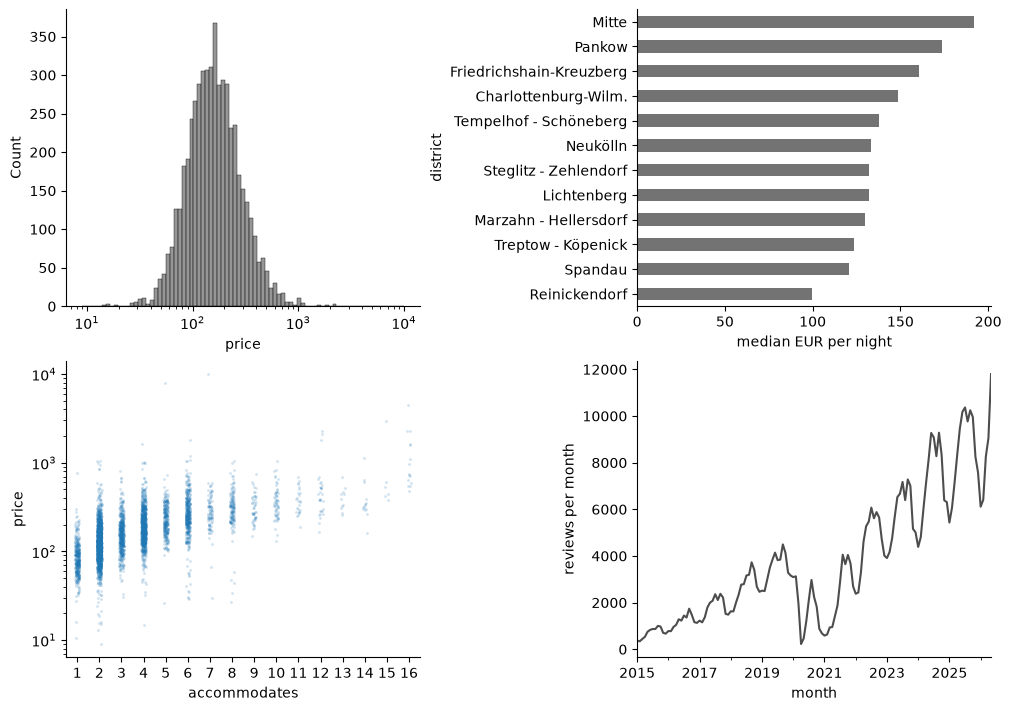

In [21]:
monthly = pd.read_parquet("case-study/data/airbnb/reviews_monthly.parquet")   # reviews per listing and month
fig, axes = plt.subplots(2, 2, figsize=(10, 7), layout="constrained")
sns.histplot(short_stay_listings, x="price", log_scale=True, color="0.45", ax=axes[0, 0])          # distribution
median_price = short_stay_listings.groupby("district")["price"].median().sort_values()
median_price.plot.barh(ax=axes[0, 1], color="0.45", xlabel="median EUR per night")  # comparison
sns.stripplot(short_stay_listings, x="accommodates", y="price", alpha=0.2, size=2, ax=axes[1, 0]).set(yscale="log")  # relationship
per_month = monthly.groupby("month")["n_reviews"].sum()
per_month.loc["2015":"2026-05"].plot(ax=axes[1, 1], color="0.3", ylabel="reviews per month")  # change over time
plt.show()

> **Note.** Write the question as a sentence above the chart before you code it. If you cannot, you are not ready to choose a chart.

### Perception and proportional ink

A chart **encodes** numbers as position, length, angle, area or colour. Cleveland and McGill (1984) measured how accurately people decode these: **position on a common scale** is read most accurately, then length, then angle and area; colour saturation is read least accurately. A bar chart uses position and length; a pie chart uses angle and area.

```mermaid
flowchart LR
    A["position on a<br/>common scale"] --> B["length"] --> C["angle, slope"] --> D["area"] --> E["colour<br/>saturation"]
```

Two further rules follow. Tufte's **data–ink ratio**: remove ink that carries no data (heavy grids, borders, 3D effects, shadows), and label values directly instead of in a distant legend. Wilke's **principle of proportional ink**: the area of a shaded region must be proportional to the value it represents, which is why **bars start at zero**. A 3D chart distorts length through perspective; a chart with two y-axes lets the author choose scales so that any two lines appear to cross.

**Predict.** In which of the two panels below can you tell faster whether Mitte or Friedrichshain-Kreuzberg has more listings?

Next we draw the same shares as a pie and as sorted bars. `ax.pie` encodes by angle; `ax.barh` by position; `ax.bar_label` writes the values at the bars; `ax.invert_yaxis()` puts the largest bar at the top.

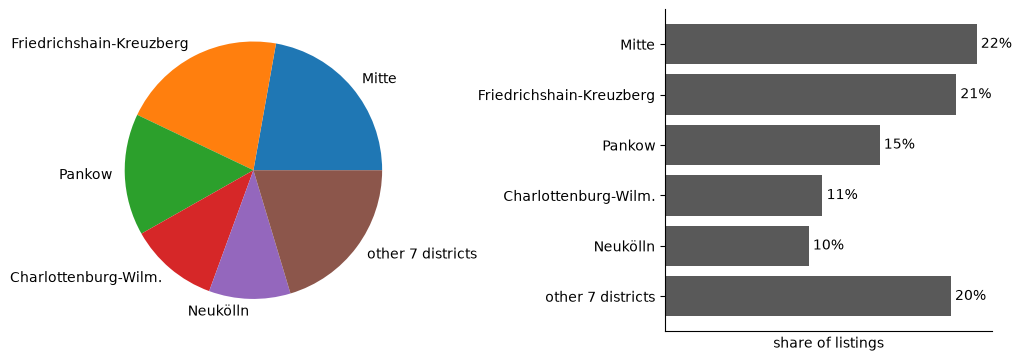

In [22]:
share = listings["district"].value_counts(normalize=True)
share = pd.concat([share.head(5), pd.Series({"other 7 districts": share.iloc[5:].sum()})])
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.5), layout="constrained")
left.pie(share, labels=share.index)
right.barh(share.index, share, color="0.35")
right.bar_label(right.containers[0], labels=[f"{v:.0%}" for v in share], padding=3)
right.set(xlabel="share of listings", xticks=[])
right.invert_yaxis()
plt.show()

### matplotlib: Figure, Axes, labels and annotation

*Partly adapted from the [Quick start guide](https://matplotlib.org/stable/users/explain/quick_start.html) (Matplotlib development team, Matplotlib licence (BSD-compatible)), applied to the Berlin listings.*

matplotlib is the base plotting library of Python; pandas and seaborn draw with it.

#### Parts of a Figure

The **Figure** is the whole figure; it keeps track of all child Axes, a group of special artists (titles, figure legends, colour bars) and even nested subfigures. An **Axes** is the region where data are plotted; it usually contains two **Axis** objects (be aware of the difference between *Axes* and *Axis*) that set scale and limits and generate ticks and tick labels. The location of the ticks is chosen by a *Locator* and their labels by a *Formatter*. Everything visible on the Figure is an **Artist**: text, lines, patches, even the Figure and Axes themselves.

#### Two interfaces: explicit and implicit

You can create Figures and Axes explicitly and call methods on them (the object-oriented, explicit style: `fig, ax = plt.subplots(); ax.plot(...)`) or rely on `pyplot` to manage them implicitly (`plt.plot(...)`, `plt.xlabel(...)`). The matplotlib documentation recommends the explicit style for complicated plots and for code meant to be reused, and the implicit style for quick interactive work. In this course we use the explicit style: `fig, ax = plt.subplots()` creates a Figure with one Axes, and we draw with methods of `ax`, so the code says which plot is changed.

#### Labels, titles and annotation

A chart for readers needs axis labels with units, readable numbers and a title; a title that states the finding tells the reader what to look for. One highlight colour and an annotation point to what matters.

Next we draw listings per district with a finding as the title. `bar.set_color` highlights single bars; `ax.annotate(text, xy=..., xytext=..., arrowprops=...)` adds a label with an arrow from `xytext` to `xy` (both in data coordinates); `ax.xaxis.set_major_formatter("{x:,.0f}")` writes 2,000 instead of 2000.

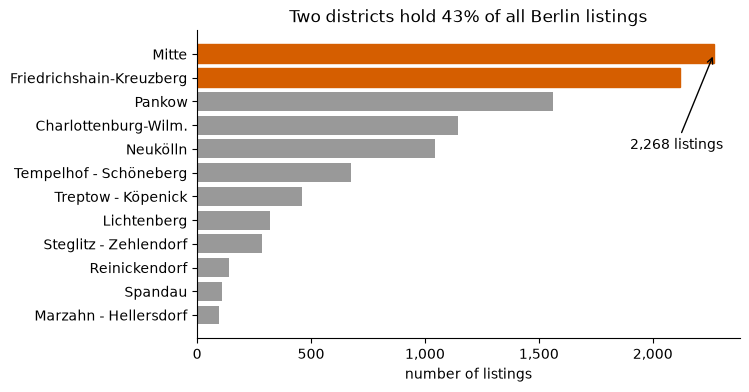

In [23]:
counts = listings["district"].value_counts()
top2 = counts.iloc[:2].sum() / counts.sum()
fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(counts.index, counts, color="0.6")
for bar in bars[:2]:
    bar.set_color("#D55E00")                                   # the two districts the title talks about
ax.invert_yaxis()
ax.set(xlabel="number of listings", title=f"Two districts hold {top2:.0%} of all Berlin listings")
ax.annotate(f"{counts.iloc[0]:,} listings", xy=(counts.iloc[0], 0), xytext=(1900, 4), arrowprops={"arrowstyle": "->"})
ax.xaxis.set_major_formatter("{x:,.0f}")
plt.show()

#### A helper function for repeated plots

If you make the same plot again and again with different data, write a function that takes the Axes as its first argument and returns what it drew. Next we use such a helper to draw two panels.

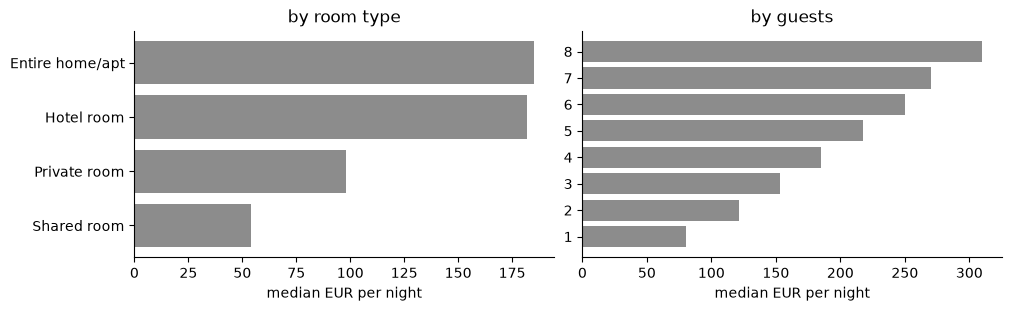

In [24]:
def median_bars(ax, series, title):
    # A helper to draw sorted horizontal median bars into a given Axes.
    s = series.sort_values()
    out = ax.barh(s.index, s, color="0.55")
    ax.set(title=title, xlabel="median EUR per night")
    return out

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3), layout="constrained")
median_bars(ax1, short_stay_listings.groupby("room_type")["price"].median(), "by room type")
median_bars(ax2, short_stay_listings.groupby("accommodates")["price"].median().loc[1:8].rename(str), "by guests")
plt.show()

#### Styling artists

Most plotting methods accept styling options (`color`, `linewidth`, `linestyle`, `marker`), and every artist has setters to change them afterwards. Colours can be names, hex codes, grey levels as strings (`"0.6"`), or the default cycle `"C0"`, `"C1"`, …. Line widths are in points (1/72 inch); `scatter` sizes are roughly proportional to the marker area.

#### Scales, ticks and dates

Besides linear scales, matplotlib offers `set_yscale("log")` and others. Tick positions can be set by hand with `set_xticks(positions, labels)`; dates get date locators and formatters. `ConciseDateFormatter` writes compact date labels.

Next we draw monthly reviews since 2019 on a linear and a log scale, with concise date labels. The log scale shows the 2020 collapse as a ratio rather than a difference.

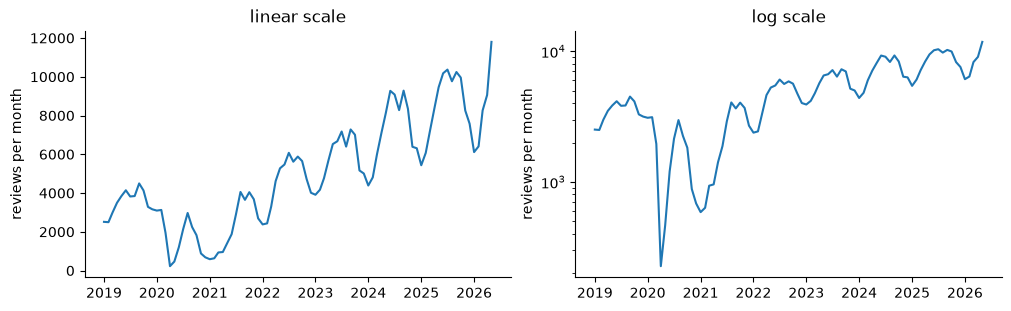

In [25]:
from matplotlib.dates import ConciseDateFormatter

recent = per_month.loc["2019":"2026-05"]
fig, axs = plt.subplots(1, 2, figsize=(10, 3), layout="constrained")
for ax, scale in zip(axs, ["linear", "log"]):
    ax.plot(recent.index, recent.values, color="C0", linewidth=1.5)
    ax.set_yscale(scale)
    ax.set(title=f"{scale} scale", ylabel="reviews per month")
    ax.xaxis.set_major_formatter(ConciseDateFormatter(ax.xaxis.get_major_locator()))
plt.show()

#### Text, maths and legends

`ax.text(x, y, s)` writes text in data coordinates, or as shares of the Axes (0 to 1) with `transform=ax.transAxes`; `ax.annotate` adds an arrow; text can contain TeX expressions between dollar signs (`r"$\mu = 158$"`); `ax.legend()` collects every artist that has a `label=`.

#### Layouts with `subplot_mosaic`

`plt.subplot_mosaic` builds layouts in which one Axes spans several rows or columns, each addressed by name. Next we put the price histogram across the left column and two small charts on the right.

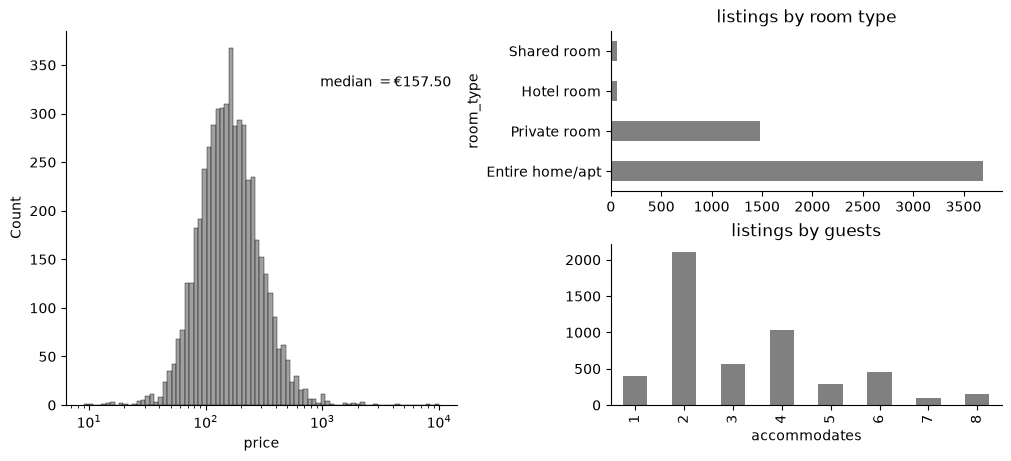

In [26]:
fig, axd = plt.subplot_mosaic([["hist", "rooms"], ["hist", "guests"]], figsize=(10, 4.5), layout="constrained")
sns.histplot(short_stay_listings, x="price", log_scale=True, color="0.5", ax=axd["hist"])
axd["hist"].text(0.65, 0.85, r"median $= €157.50$", transform=axd["hist"].transAxes)
short_stay_listings["room_type"].value_counts().plot.barh(ax=axd["rooms"], color="0.5", title="listings by room type")
short_stay_listings["accommodates"].value_counts().sort_index().loc[1:8].plot.bar(ax=axd["guests"], color="0.5", title="listings by guests")
plt.show()

#### A second y-axis

`ax.twinx()` adds a second y-axis to the same Axes. Use it rarely: two scales chosen by the author can make any two lines appear to cross. `ax.secondary_xaxis` shows the same data in a second unit (for example EUR and USD), which is harmless.

#### Colour-mapped data

`pcolormesh`, `imshow`, `contourf` and `scatter(..., c=values)` map a third variable to colour through a colour map (`cmap`) and a normalisation (`vmin`/`vmax`, or `norm=LogNorm()` for a log mapping); `fig.colorbar` adds the key. The section on scatter plots below uses a hexbin plot with a log colour scale.

> 📖 **Read more:** [extras/05-matplotlib-quick-start.ipynb](extras/05-matplotlib-quick-start.ipynb) (matplotlib documentation): the original quick start guide with all examples.

### Colour and accessibility

*Partly adapted from [Choosing color palettes](https://seaborn.pydata.org/tutorial/color_palettes.html) (Michael Waskom, BSD-3-Clause) and [Choosing Colormaps in Matplotlib](https://matplotlib.org/stable/users/explain/colors/colormaps.html) (Matplotlib development team, Matplotlib licence (BSD-compatible)), applied to the Berlin listings.*

#### Hue, saturation and lightness

Screens mix red, green and blue light, but for perception it is better to think of **hue** (what we name: red, blue), **saturation** or chroma (how colourful), and **lightness** (from black to white).

#### Three jobs for colour

Colour has three jobs:

- a **qualitative** palette separates unordered categories by hue;
- a **sequential** palette (light to dark, such as viridis) shows ordered magnitudes;
- a **diverging** palette uses two hues around a meaningful midpoint (0, a target, an average) for values above and below it.

#### Vary hue to distinguish categories

Our visual system prioritises colour differences: a few orange points among blue ones "pop out". Hue suits categories because most people distinguish a moderate number of hues and points of similar lightness look equally important. With more than a handful of colours, readers must keep referring to the legend; and not everyone sees colours the same way, so vary shape as well where it matters.

#### Vary lightness to represent numbers

Hue is poorly suited to numeric data. Next we draw where the listings are, as a two-dimensional histogram of latitude and longitude, once with a hue-based circular palette (`"hls"`) and once with a lightness-based one (`"rocket_r"`).

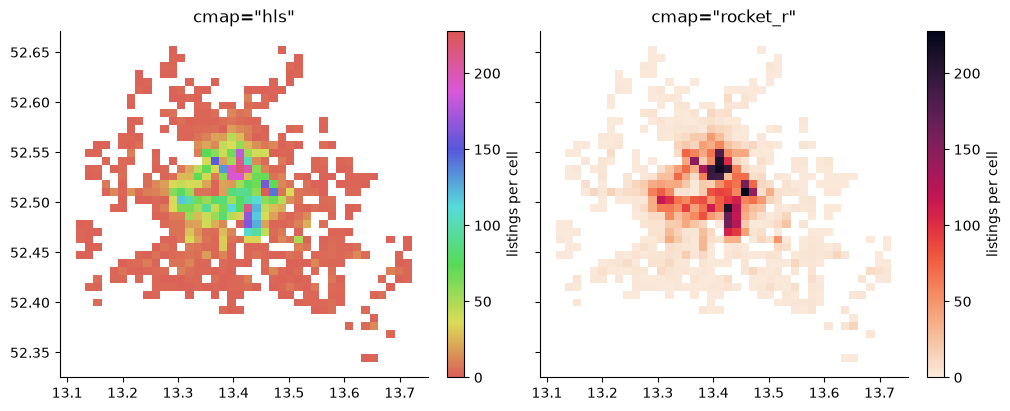

In [27]:
fig, axs = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True, layout="constrained")
for ax, cmap in zip(axs, ["hls", "rocket_r"]):
    sns.histplot(listings, x="longitude", y="latitude", bins=40, cmap=cmap, cbar=True, ax=ax,
                 cbar_kws={"label": "listings per cell"})
    ax.set(title=f'cmap="{cmap}"', xlabel="", ylabel="")
plt.show()

**What do you see?** In which panel can you find the densest part of Berlin at a glance?

With the hue palette it is hard to see where most listings are; with the lightness palette the dense centre stands out at once. Varying lightness reveals structure, and readers intuitively read darker (or brighter) as "more".

#### Palettes in seaborn and matplotlib

For qualitative palettes, seaborn's default has ten hues in the order of matplotlib's `"tab10"`, in six variants (`deep`, `muted`, `pastel`, `bright`, `dark`, `colorblind`) that differ in lightness and saturation. Circular systems (`"husl"`) give any number of evenly spaced hues of similar intensity; Color Brewer offers `"Set2"`, `"Paired"` and more.

Sequential palettes should be **perceptually uniform**: equal steps in the data look like equal steps in colour. seaborn ships `"rocket"`, `"mako"`, `"flare"` and `"crest"`; matplotlib ships `"viridis"`, `"magma"`, `"cividis"` and others. `"rocket"` and `"mako"` span a wide lightness range and suit heatmaps; their extremes come close to white, so for lines and points `"flare"` and `"crest"` are better. Every map has a reversed version with the suffix `_r`.

Diverging palettes need two dominant hues of similar lightness at the poles and a de-emphasised midpoint: `"vlag"`, `"icefire"`, `"coolwarm"`, or `sns.diverging_palette(h_neg, h_pos)`. Avoid red against green.

Next we display some palettes. `sns.color_palette(name, n)` returns a list of colours; `.as_hex()` prints their codes.

In [28]:
for name in ["colorblind", "husl", "Set2", "rocket", "crest", "vlag"]:
    print(f"{name:>10}:", sns.color_palette(name, 6).as_hex())

colorblind: ['#0173b2', '#de8f05', '#029e73', '#d55e00', '#cc78bc', '#ca9161']
      husl: ['#f77189', '#bb9832', '#50b131', '#36ada4', '#3ba3ec', '#e866f4']
      Set2: ['#66c2a5', '#fc8d62', '#8da0cb', '#e78ac3', '#a6d854', '#ffd92f']
    rocket: ['#35193e', '#701f57', '#ad1759', '#e13342', '#f37651', '#f6b48f']
     crest: ['#7dba91', '#59a590', '#40908e', '#287a8c', '#1c6488', '#254b7f']
      vlag: ['#6e90bf', '#aab8d0', '#e4e5eb', '#f2dfdd', '#d9a6a4', '#c26f6d']


#### Lightness and greyscale

The matplotlib documentation measures the lightness L* of every colour map in the CAM02-UCS colour space. Perceptually uniform maps such as viridis increase lightness steadily; `jet`, `hsv` and `turbo` go from dark to light and back, which creates apparent boundaries where the data change smoothly and makes them unreadable when printed in grey. A rough check is possible without extra packages: next we convert two colour maps to grey with the standard luminance weights of the sRGB colour space (0.2126 R + 0.7152 G + 0.0722 B) and plot the result.

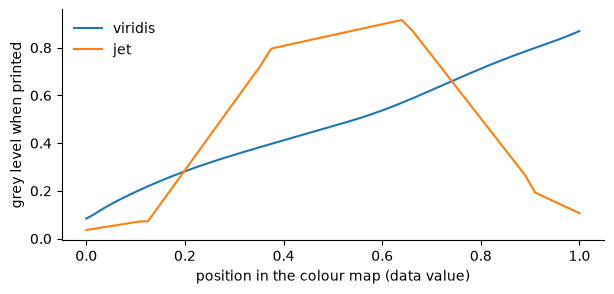

In [29]:
import matplotlib as mpl

x = np.linspace(0, 1, 256)
fig, ax = plt.subplots(figsize=(7, 3))
for name in ["viridis", "jet"]:
    rgb = mpl.colormaps[name](x)[:, :3]
    grey = rgb @ np.array([0.2126, 0.7152, 0.0722])          # relative luminance of each colour
    ax.plot(x, grey, label=name)
ax.set(xlabel="position in the colour map (data value)", ylabel="grey level when printed")
ax.legend(frameon=False)
plt.show()

Viridis prints as a steady ramp from dark to light; jet rises and falls, so two very different values can print as the same grey. matplotlib replaced jet with viridis as its default colour map in version 2.0 for these reasons.

#### Colour vision deficiency and direct labels

About 1 in 12 men has a colour vision deficiency, most often difficulty telling red from green (National Eye Institute, *Color Blindness*, checked 14 October 2026). Palettes such as **Okabe–Ito** (seaborn's `"colorblind"` palette is close to it) stay distinguishable for them. Colour should never be the only carrier of meaning: add direct labels, position, marker shape or line style, and keep one fixed colour per category across all charts of a report.

Next we draw the room-type mix per district as stacked bars in Okabe–Ito colours with labels written on the chart instead of a legend. A dict passed as `color=` fixes one colour per column; `ax.text(x, y, s)` writes text at data coordinates, here inside the top bar.

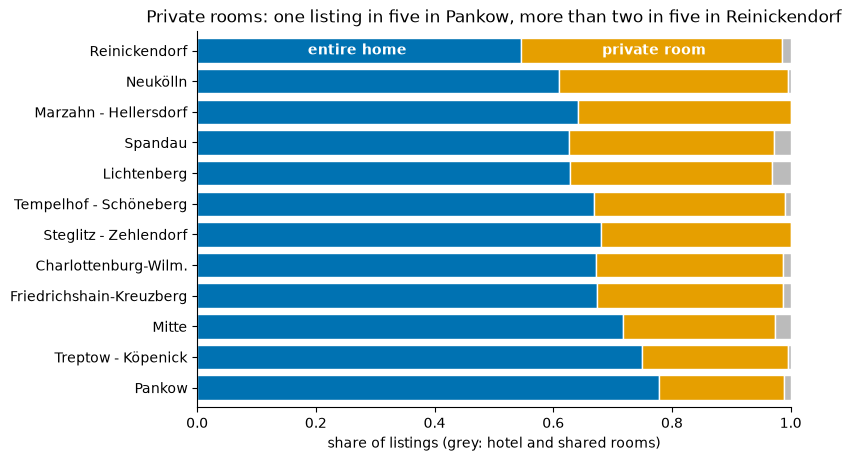

In [30]:
OKABE_ITO = {"Entire home/apt": "#0072B2", "Private room": "#E69F00", "other": "#BBBBBB"}
group = listings["room_type"].where(listings["room_type"].isin(["Entire home/apt", "Private room"]), "other")
mix3 = pd.crosstab(listings["district"], group, normalize="index")[list(OKABE_ITO)].sort_values("Private room")
fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
mix3.plot.barh(stacked=True, ax=ax, width=0.8, color=OKABE_ITO, edgecolor="white", legend=False)
for label, x in [("entire home", 0.27), ("private room", 0.77)]:
    ax.text(x, len(mix3) - 1, label, ha="center", va="center", color="white", fontweight="bold")
ax.set(xlabel="share of listings (grey: hotel and shared rooms)", ylabel="",
       title="Private rooms: one listing in five in Pankow, more than two in five in Reinickendorf")
plt.show()

> 📖 **Read more:** [extras/06-seaborn-color-palettes.ipynb](extras/06-seaborn-color-palettes.ipynb) (seaborn documentation): all palette families with their parameters (cubehelix, light and dark palettes, custom diverging palettes). [extras/07-matplotlib-colormaps.ipynb](extras/07-matplotlib-colormaps.ipynb) (matplotlib documentation): every colour map with its lightness curve, greyscale conversion and simulations of colour vision deficiencies (needs `colorspacious`).

### seaborn: statistical charts and small multiples

**seaborn** draws statistical charts from a DataFrame in long format (one row per observation): you name the columns for `x`, `y`, colour (`hue`) and panels (`col`, `row`). **Axes-level** functions (`histplot`, `boxplot`, `scatterplot`) draw into one Axes; **figure-level** functions (`displot`, `catplot`, `relplot`, `lmplot`) create a whole grid of Axes and return it. **Small multiples** are small charts with the same axes, one per group; the eye compares shapes across panels instead of decoding overlapping colours, and they scale to many groups where colour fails beyond four or five.

Next we draw one price histogram per room type. `col_order` fixes the panel order; the returned grid has methods such as `set_axis_labels`.

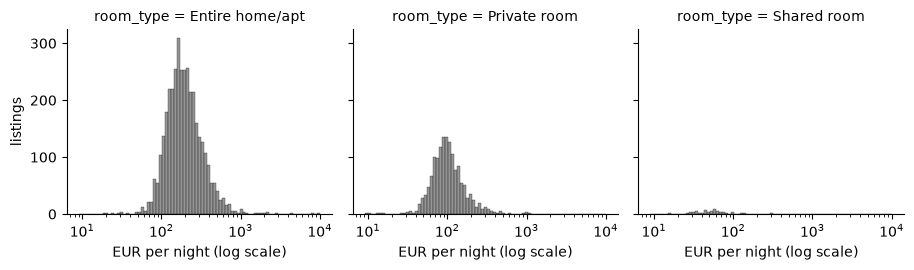

In [31]:
g = sns.displot(short_stay_listings, x="price", col="room_type", col_order=["Entire home/apt", "Private room", "Shared room"],
                log_scale=True, height=2.8, aspect=1.1, color="0.45")
g.set_axis_labels("EUR per night (log scale)", "listings")
plt.show()

Shared axes make panels comparable. With `facet_kws={"sharey": False}` each panel gets its own scale: the shape within each panel becomes visible, but the panels no longer show that one group is far larger. Say so in the caption.

### Interactive charts with Plotly Express

*Partly adapted from [Styling Plotly Express Figures in Python](https://plotly.com/python/styling-plotly-express/) (Plotly, MIT), applied to the Berlin listings.*

**Plotly Express** (`plotly.express as px`) draws an interactive chart in one call, with arguments similar to seaborn (`x`, `y`, `color`, `facet_col`). Readers can hover to read exact values, zoom, and hide a series by clicking the legend. A Plotly figure consists of **traces** (one per series, in `fig.data`) and a **layout** (axes, title, legend). Interactive charts are the building blocks of the dashboard in block 2. Hover text is invisible in a printed report, so the default view must already show the finding.

Next we draw reviews per month for four districts. `DataFrame.merge` adds the district to every monthly row; `px.line(df, x=..., y=..., color=...)` draws one line per district; `fig.update_layout(hovermode="x unified")` shows all four values for the month under the mouse.

In [32]:
import plotly.express as px
import plotly.io as pio

pio.renderers.default = "plotly_mimetype+notebook_connected"   # small output that JupyterLab and VS Code render
districts = ["Mitte", "Friedrichshain-Kreuzberg", "Pankow", "Neukölln"]
by_month = (monthly.merge(listings[["id", "district"]], left_on="listing_id", right_on="id")
            .query("district in @districts and '2015-01-01' <= month <= '2026-05-01'")
            .groupby(["district", "month"], as_index=False)["n_reviews"].sum())
fig = px.line(by_month, x="month", y="n_reviews", color="district", category_orders={"district": districts},
              color_discrete_sequence=["#0072B2", "#E69F00", "#009E73", "#D55E00"],
              labels={"month": "", "n_reviews": "reviews per month"}, height=350)
fig.update_layout(hovermode="x unified")
fig.show()

#### Four ways to style a figure

Every Plotly Express function returns a `plotly.graph_objects.Figure` whose `data` and `layout` are pre-populated from the arguments. There are four ways to style it:

1. **Built-in arguments** of every `px` function: `title`, `width` and `height`; `template` (many styling settings at once); `labels` (a dict that renames axis, legend and hover labels); `category_orders` (a dict of column → list of values in the desired order, applied to axes, legends, facets and stacks); `hover_data` and `hover_name`; and colour arguments such as `color_discrete_sequence`, `color_discrete_map` (value → colour) and `color_continuous_scale`.
2. **Update methods** on the returned figure: `update_layout`, `update_xaxes`, `update_yaxes`, `add_shape`, `add_annotation` and more.
3. **Templates**: `template="simple_white"`, `"plotly_white"`, `"ggplot2"`, `"seaborn"`, …; a template also sets the default colour sequence and continuous colour scale.
4. **Defaults** for a whole session: `px.defaults.template`, `px.defaults.width`, `px.defaults.height`, `px.defaults.color_continuous_scale`.

Next we draw the median price per district and room type with built-in styling arguments. `color_discrete_map` fixes one colour per room type; `category_orders` sorts the districts; `template="simple_white"` removes the grey background.

In [33]:
med = (two.groupby(["district", "room_type"], as_index=False)["price"].median())
district_order = med[med["room_type"] == "Entire home/apt"].sort_values("price")["district"].tolist()
fig = px.bar(med, x="price", y="district", color="room_type", barmode="group", orientation="h",
             title="Median price per short-stay night by district and room type",
             labels={"price": "median EUR per night", "district": "", "room_type": "room type"},
             category_orders={"district": district_order, "room_type": ["Entire home/apt", "Private room"]},
             color_discrete_map={"Entire home/apt": "#0072B2", "Private room": "#E69F00"},
             template="simple_white", height=450)
fig.show()

#### Updating a figure after it is drawn

Next we modify the same figure afterwards: `update_xaxes(tickprefix="€")` adds a currency sign, `update_layout(legend=...)` moves the legend above the plot, `add_shape` draws a reference line at the citywide median for entire homes (in "paper" coordinates for y, so it spans the whole plot), and `add_annotation` labels it.

In [34]:
city = two.loc[two["room_type"] == "Entire home/apt", "price"].median()
fig.update_xaxes(tickprefix="€", showgrid=True)
fig.update_layout(legend=dict(title=None, orientation="h", y=1, yanchor="bottom", x=0.5, xanchor="center"))
fig.add_shape(type="line", x0=city, x1=city, y0=0, y1=1, yref="paper", line_dash="dot", line_color="grey")
fig.add_annotation(x=city, y=1, yref="paper", text=f"Berlin median, entire homes: €{city:.0f}", showarrow=False, yshift=10)
fig.show()

> 📖 **Read more:** [extras/08-plotly-express.ipynb](extras/08-plotly-express.ipynb) (Plotly documentation): a gallery of Plotly Express chart types, from facets to maps and animations (one image cell needs `scikit-image`). [extras/09-plotly-express-styling.ipynb](extras/09-plotly-express-styling.ipynb) (Plotly documentation): the original styling guide with templates and defaults.

### Critique and improve a chart

Four questions find most problems in a chart:

1. **Question**: which comparison should the reader make?
2. **Encoding**: is that comparison shown by position or length on a common scale?
3. **Accuracy**: do the bars start at zero; are units and the population stated?
4. **Clarity**: is there anything the reader must decode that could be labelled directly?

The left chart below shows reviews per year with an axis that starts at 20,000, rainbow colours that encode nothing and a title that says nothing. The right one starts at zero, uses one colour for the two pandemic years and states the finding.

![A poorly designed bar chart of reviews per year with a truncated axis and rainbow colours next to an improved bar chart from zero with the pandemic years highlighted](../figures/good-vs-poor-chart.png)

Next we draw the improved version. `Series.groupby(series.dt.year)` groups monthly rows by calendar year; a list comprehension builds one colour per bar.

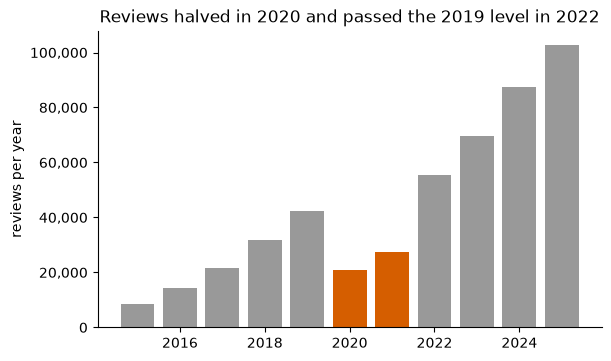

{2019: 42219, 2020: 20804, 2021: 27425, 2022: 55428}


In [35]:
yearly = monthly.groupby(monthly["month"].dt.year)["n_reviews"].sum().loc[2015:2025]
colours = ["#D55E00" if year in (2020, 2021) else "0.6" for year in yearly.index]
fig, ax = plt.subplots(figsize=(6, 3.5), layout="constrained")
ax.bar(yearly.index, yearly, color=colours)
ax.yaxis.set_major_formatter("{x:,.0f}")
ax.set(ylabel="reviews per year", title="Reviews halved in 2020 and passed the 2019 level in 2022")
plt.show()
print(yearly.loc[[2019, 2020, 2021, 2022]].to_dict())

A caption would add the limitation: the file contains only listings that still exist in 2026, so earlier years are undercounted. A line chart need not start at zero when the reader compares changes rather than magnitudes, but then the axis must make the range obvious. Bars always start at zero.

## Relationships between numeric variables

### Scatter plots

A **scatter plot** places one point per observation at (x, y). Read it for **direction** (up, down, none), **form** (straight, curved, clusters), **strength** (how tightly the points follow the form) and **unusual points** (outliers, points with extreme x). Put the variable you think of as the predictor on the x-axis and the outcome on the y-axis; it proves nothing, but it matches how regression is written.

With thousands of points they overlap (**overplotting**) and the plot shows only the outline of the data. Remedies: transparency, a random subsample, a little random **jitter** for integer values, a **hexbin** plot that counts points per hexagon, or binned summaries (next section).

Next we plot the log price against the number of guests in two ways. `rng.uniform(-0.3, 0.3, n)` draws the jitter; `ax.scatter(..., alpha=0.1)` makes points transparent; `ax.hexbin(..., bins="log")` colours hexagons by the log of their count.

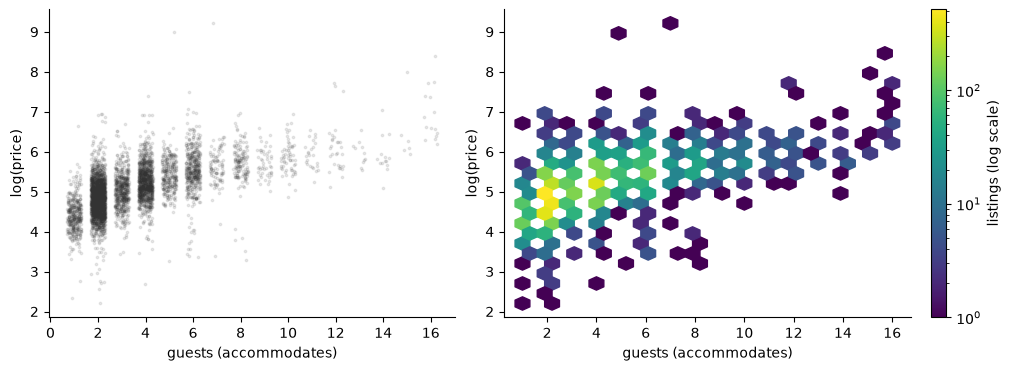

In [36]:
rng = np.random.default_rng(0)
x, y = short_stay_listings["accommodates"], short_stay_listings["log_price"]
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.6), layout="constrained")
left.scatter(x + rng.uniform(-0.3, 0.3, len(x)), y, s=3, alpha=0.1, color="0.2")
hb = right.hexbin(x, y, gridsize=25, bins="log", cmap="viridis")
fig.colorbar(hb, ax=right, label="listings (log scale)")
for ax in (left, right):
    ax.set(xlabel="guests (accommodates)", ylabel="log(price)")
plt.show()

### Binned percentiles

A scatter plot of thousands of points shows the outline but not the typical value. Downey's *Think Stats* (chapter 7) draws **decile plots**: cut x into bins and draw, per bin, the 10th, 50th and 90th percentile of y. In our own code: next we compute the percentiles of the price per number of guests, keeping only sizes with at least 30 listings. `groupby(...).quantile([...]).unstack()` gives one column per percentile.

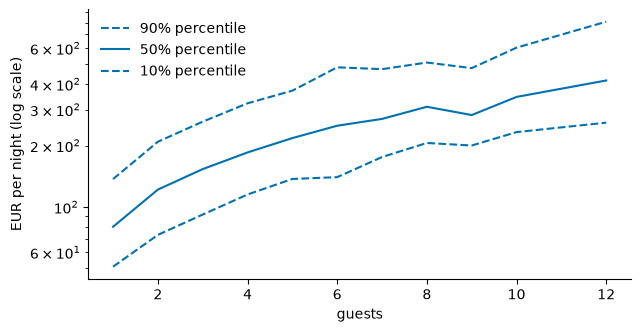

In [37]:
sizes = short_stay_listings["accommodates"].value_counts()
keep_sizes = sizes[sizes >= 30].index
pct = (short_stay_listings[short_stay_listings["accommodates"].isin(keep_sizes)].groupby("accommodates")["price"]
       .quantile([0.1, 0.5, 0.9]).unstack())
fig, ax = plt.subplots(figsize=(7, 3.5))
for q, style in [(0.9, "--"), (0.5, "-"), (0.1, "--")]:
    ax.plot(pct.index, pct[q], style, color="#0072B2", label=f"{q:.0%} percentile")
ax.set(yscale="log", xlabel="guests", ylabel="EUR per night (log scale)")
ax.legend(frameon=False)
plt.show()

**What do you see?** Do all three percentile lines rise with the number of guests, or only the median?

The median rises steadily with the number of guests, and so do the 10th and 90th percentiles: the whole distribution shifts. Above about eight guests the bins are small and the lines become noisy.

### Pearson and Spearman correlation

- **Pearson's r** measures how closely the points follow a **straight line**, from −1 (perfect falling line) through 0 to +1 (perfect rising line). It is the average product of the standardised x and y values: points in the upper right and lower left pull it up, points in the other two quadrants pull it down.
- **Spearman's ρ** (rho) is Pearson's r computed on the **ranks**. It captures any **monotonic** relationship (always up or always down, not necessarily straight) and resists outliers.

Neither is a slope: r = 0.9 can mean a rise of 1 cent or of €1,000 per unit of x; the slope is regression's job (block 2). And r misses curves: a relationship can be perfect and still have r close to 0.

**Predict.** For x = 1, 2, …, 10 and y = eˣ (a curve that always rises, ever more steeply), which coefficient is 1, and which is clearly below 1?

Next we check. `stats.pearsonr(x, y)` and `stats.spearmanr(x, y)` return a result whose `.statistic` is the coefficient.

In [38]:
xs = np.arange(1, 11)
ys = np.exp(xs)
print("Pearson:", round(stats.pearsonr(xs, ys).statistic, 2), "| Spearman:", round(stats.spearmanr(xs, ys).statistic, 2))

Pearson: 0.72 | Spearman: 1.0


The relationship is perfectly monotonic, so the ranks agree completely and Spearman's ρ is 1; it is not a straight line, so Pearson's r is below 1. Now the real data: how strongly does the price rise with the number of guests? `res.confidence_interval()` gives a 95 % interval for Pearson's r; `Series.nlargest(5).index` finds the five most expensive listings, which we then leave out with `~index.isin(...)`.

In [39]:
guests, price = short_stay_listings["accommodates"], short_stay_listings["price"]
print("Pearson, raw price:  ", round(stats.pearsonr(guests, price).statistic, 3))
print("Spearman:            ", round(stats.spearmanr(guests, price).statistic, 3))
res = stats.pearsonr(guests, np.log(price))
ci = res.confidence_interval()
print("Pearson, log price:  ", round(res.statistic, 3), "95 % CI", round(ci.low, 3), "to", round(ci.high, 3))
keep = ~price.index.isin(price.nlargest(5).index)
print("Pearson, raw, without the 5 most expensive:", round(stats.pearsonr(guests[keep], price[keep]).statistic, 3))

Pearson, raw price:   0.398
Spearman:             0.643
Pearson, log price:   0.603 95 % CI 0.585 to 0.62
Pearson, raw, without the 5 most expensive: 0.578


Three coefficients, one scatter plot. On raw prices, five listings out of 5,302 hold Pearson's r down; without them it jumps. Spearman and Pearson on the log price are not fooled. The relationship is clearly positive and fairly strong. It is still not causal: larger listings are also more often entire homes and may lie in more central buildings, and adding a bed to a flat does not raise its market price by the slope of the line.

Is the rating related to the price? Next we compute Spearman's ρ between the average rating and the price, and between the rating and the price per guest.

In [40]:
rated = short_stay_listings.dropna(subset=["review_scores_rating"])
print("rating vs price:          ", round(stats.spearmanr(rated["review_scores_rating"], rated["price"]).statistic, 3))
print("rating vs price per guest:", round(stats.spearmanr(rated["review_scores_rating"],
                                                         rated["price"] / rated["accommodates"]).statistic, 3))

rating vs price:           0.048
rating vs price per guest: 0.177


Both coefficients are small (0.05 and 0.18): ratings and prices show no, or at most a weak, monotonic relationship. A useful reminder that "no correlation" is a finding too.

#### r² and the strength of a correlation

r² is the share of the variance of y that a straight line in x explains: r = 0.6 explains 36 %, r = 0.3 only 9 %. Which r counts as "strong" depends on the field; report the scatter plot with it. With thousands of observations even r = 0.05 is "significant" (see *Is a correlation larger than chance?* below) while explaining a quarter of a percent of the variance.

> 📖 **Read more:** [extras/10-correlation.ipynb](extras/10-correlation.ipynb) (Think Stats, chapter 7): scatter plots with jitter and transparency, decile plots, Pearson's and Spearman's correlation and their weaknesses, on survey data.

### Covariance and correlation matrices

*Partly adapted from [Introduction to Probability and Statistics](https://github.com/microsoft/Data-Science-For-Beginners/blob/main/1-Introduction/04-stats-and-probability/notebook.ipynb) (Microsoft, MIT).*

The **covariance** of x and y is the average product of their deviations from their means. Its sign shows the direction, but its size depends on the units (euros times guests), so it is hard to read. Dividing by both standard deviations gives Pearson's r, which has no unit. `np.cov` returns a **covariance matrix**: entry (i, j) is the covariance of variables i and j, and the diagonal holds the variances. `np.corrcoef` returns the correlation matrix, with ones on the diagonal. Missing values make the result `nan`, so drop them first.

Next we compute both for guests and log price.

In [41]:
xy = short_stay_listings[["accommodates", "log_price"]].dropna()
print("covariance matrix:\n", np.cov(xy["accommodates"], xy["log_price"]).round(3))
print("correlation matrix:\n", np.corrcoef(xy["accommodates"], xy["log_price"]).round(3))

covariance matrix:
 [[5.384 0.835]
 [0.835 0.356]]
correlation matrix:
 [[1.    0.603]
 [0.603 1.   ]]


#### All pairwise correlations as a heatmap

A pandas DataFrame computes all pairwise correlations at once: `df.corr(method="spearman")`. Next we draw them as a heatmap with a diverging palette centred at 0. `sns.heatmap(..., center=0, annot=True)` writes the values into the cells.

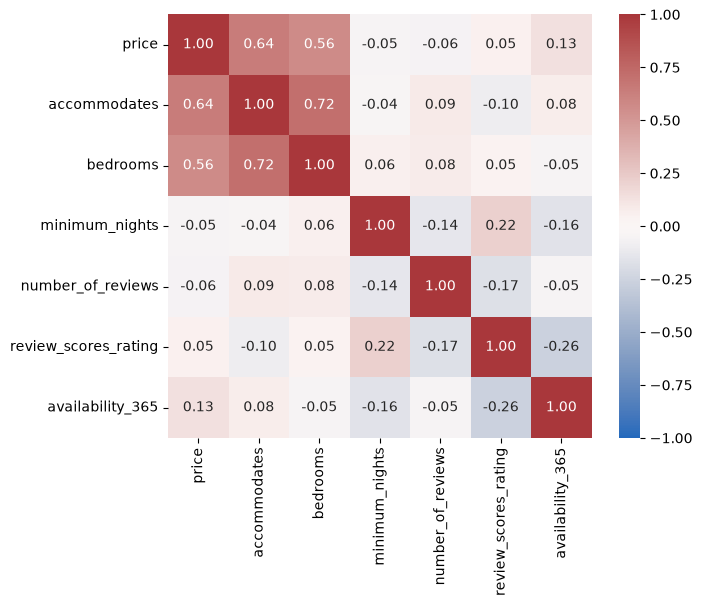

In [42]:
num = short_stay_listings[["price", "accommodates", "bedrooms", "minimum_nights", "number_of_reviews",
             "review_scores_rating", "availability_365"]]
corr = num.corr(method="spearman")
fig, ax = plt.subplots(figsize=(7, 5.5))
sns.heatmap(corr, cmap="vlag", center=0, vmin=-1, vmax=1, annot=True, fmt=".2f", square=True, ax=ax)
plt.show()

**What do you see?** Which pair of variables has the darkest cell off the diagonal?

A correlation matrix is a screening tool: it points to pairs worth plotting (guests and bedrooms are strongly related, so they carry much the same information) and to candidate predictors for Session 6. It is not a list of causes.

### Is a correlation larger than chance?

*Adapted from [Pearson's Correlation](https://docs.scipy.org/doc/scipy/tutorial/stats/hypothesis_pearsonr.html) (SciPy developers, BSD-3-Clause). The logic of a test is the subject of block 2; this section is a preview.*

#### An example: proline and collagen in livers

Consider data from a study of the relationship between free proline (an amino acid) and total collagen (a protein often found in connective tissue) in unhealthy human livers (Kershenobich, Fierro & Rojkind, 1970). The observations are paired: each free proline measurement was taken from the same liver as the total collagen measurement at the same index.

In [43]:
# total collagen (mg/g dry weight of liver)
x = np.array([7.1, 7.1, 7.2, 8.3, 9.4, 10.5, 11.4])
# free proline (μ mole/g dry weight of liver)
y = np.array([2.8, 2.9, 2.8, 2.6, 3.5, 4.6, 5.0])
res = stats.pearsonr(x, y)
print(round(res.statistic, 3))

0.935


#### The null distribution and the p-value

The test compares the observed statistic with the **null distribution**: the distribution of values the statistic takes under the null hypothesis, here that the two measurements are drawn from independent normal distributions. Under that hypothesis the sample correlation follows a beta distribution on (−1, 1) with shape parameters a = b = n/2 − 1. The **p-value** is the share of the null distribution that is as extreme as or more extreme than the observed value; in a two-sided test, both tails count.

Next we draw the null distribution and shade the two tails. `stats.beta(a, b, loc=-1, scale=2)` defines the distribution on (−1, 1); `dist.cdf` and `dist.sf` give the probability below and above a value.

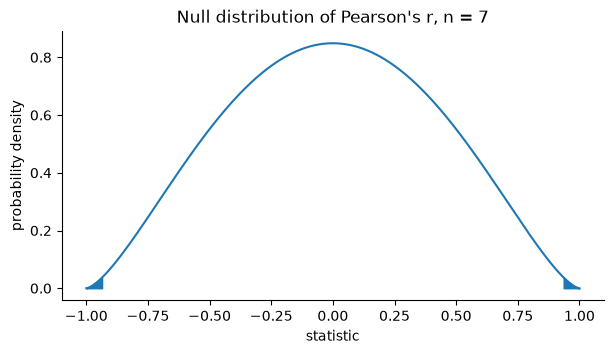

p-value (two-sided): 0.002 | scipy: 0.002


In [44]:
n = len(x)
dist = stats.beta(a=n / 2 - 1, b=n / 2 - 1, loc=-1, scale=2)
r_vals = np.linspace(-1, 1, 1000)
pdf = dist.pdf(r_vals)
rs = res.statistic
fig, ax = plt.subplots(figsize=(7, 3.5))
ax.plot(r_vals, pdf)
ax.fill_between(r_vals[r_vals >= rs], 0, pdf[r_vals >= rs], color="C0")
ax.fill_between(r_vals[r_vals <= -rs], 0, pdf[r_vals <= -rs], color="C0")
ax.set(title="Null distribution of Pearson's r, n = 7", xlabel="statistic", ylabel="probability density")
plt.show()
print("p-value (two-sided):", round(dist.cdf(-rs) + dist.sf(rs), 4), "| scipy:", round(res.pvalue, 4))

If the p-value is small, this may be taken as evidence against the null hypothesis. Note that:

- the inverse is not true: a large p-value is not evidence *for* the null hypothesis;
- the threshold for "small" should be chosen before the data are analysed, weighing the risk of false positives against false negatives;
- small p-values are not evidence for a large effect, only for an effect that is unlikely under the null hypothesis.

#### One-sided and permutation tests

If the researchers had predicted a positive correlation in advance, a **one-sided** test (`alternative="greater"`) counts only the upper tail, halving the p-value. If normality is doubtful, a **permutation test** builds the null distribution from the data themselves: under independence every pairing of x and y values is equally likely, so we compute r for all pairings. `method=stats.PermutationMethod()` does this.

In [45]:
print("one-sided:", round(stats.pearsonr(x, y, alternative="greater").pvalue, 5))
print("permutation, one-sided:", round(stats.pearsonr(x, y, alternative="greater",
                                                      method=stats.PermutationMethod()).pvalue, 5))

one-sided: 0.00101
permutation, one-sided: 0.00556


The same tutorial for Spearman's ρ uses the t distribution with n − 2 degrees of freedom as the large-sample null distribution and a permutation test for small samples.

On our listings, the p-value of the guests–price correlation is far below any threshold: with 5,302 listings, the question is not whether r differs from 0 but how large it is and what drives it.

> 📖 **Read more:** [extras/11-pearson-correlation-test.ipynb](extras/11-pearson-correlation-test.ipynb) and [extras/12-spearman-correlation-test.ipynb](extras/12-spearman-correlation-test.ipynb) (SciPy documentation): the full tutorials, including a Monte Carlo check of the null distribution.

### Confounding and Simpson's paradox

A **confounder** is a third variable that is related to both variables of interest and creates or distorts the relationship between them. **Simpson's paradox** is the extreme case: a relationship in the pooled data vanishes or reverses within every subgroup.

The classic case is the 1973 graduate admissions at UC Berkeley (Bickel, Hammel & O'Connell, 1975). Pooled over the six largest departments, about 45 % of male and 30 % of female applicants were admitted, yet within four of the six departments women were admitted at a higher rate. Women had applied more often to the departments that rejected most applicants; the department was the confounder. A medical example: in a comparison of kidney-stone treatments (Charig et al., 1986), one treatment had higher success rates for both small and large stones but looked worse pooled, because it was used more often for the harder large stones.

![Left: Berkeley admission rates by department for men and women. Right: mean price in two Berlin districts for short stays, medium-term listings and all listings](../figures/simpsons-paradox.png)

#### A Berlin district pair

The listings contain a milder version. Among all priced listings, Friedrichshain-Kreuzberg looks more expensive than Charlottenburg-Wilmersdorf. Is it, for the same type of stay?

Next we compare the mean price pooled and within each type of stay. `np.where(condition, a, b)` labels the rows; `groupby([...]).mean().unstack()` turns the second grouping level into columns.

In [46]:
priced = listings[listings["price"].notna()].copy()
priced["stay"] = np.where(priced["minimum_nights"].ge(28), "medium-term", "short")
pair = priced[priced["district"].isin(["Friedrichshain-Kreuzberg", "Charlottenburg-Wilm."])]
print("pooled:", pair.groupby("district")["price"].mean().round(1).to_dict())
print(pair.groupby(["district", "stay"])["price"].mean().unstack().round(1))
print("share medium-term:", pair.groupby("district")["stay"].apply(lambda s: (s == "medium-term").mean()).round(2).to_dict())

pooled: {'Charlottenburg-Wilm.': 141.9, 'Friedrichshain-Kreuzberg': 157.4}
stay                      medium-term  short
district                                    
Charlottenburg-Wilm.             32.6  186.1
Friedrichshain-Kreuzberg         33.2  189.4
share medium-term: {'Charlottenburg-Wilm.': 0.29, 'Friedrichshain-Kreuzberg': 0.2}


Pooled, Friedrichshain-Kreuzberg is about €15 more expensive. Within each type of stay the gap shrinks to a few euros (about €3 for short stays, under €1 for medium-term listings). Most of the pooled gap comes from the mix: Charlottenburg-Wilmersdorf has a larger share of medium-term listings with their low price field (29 % against 20 %). The honest summary is "the gap mostly vanishes", not "the order reverses": this is confounding, but not a full Simpson's paradox.

Before acting on any relationship, ask what else differs between the groups. This question is the reason for randomised experiments (A/B tests, block 2) and for control variables in regression (Session 6). Adjusting is not always right, though: adjusting for a variable that is itself caused by the variable of interest (a **mediator** or a **collider**) can create bias. Draw the causal story before deciding what to hold fixed.

## Worked example · What does a night in Berlin cost, and where?

A city housing analyst asks three questions: what does a short-stay night cost by room type, which districts are most expensive, and how much more does a larger listing cost? We answer with robust summaries, a chart that shows the counts behind each median, and binned medians.

### Step 1 · Robust price summary by room type

Next we summarise the price by room type. `groupby(...).agg(name=(column, function))` gives named result columns; a `lambda` computes a quantile.

In [47]:
(short_stay_listings.groupby("room_type")
 .agg(n=("price", "size"), p10=("price", lambda s: s.quantile(0.1)),
      median=("price", "median"), p90=("price", lambda s: s.quantile(0.9)))
 .sort_values("median", ascending=False).round(0))

,n,p10,median,p90
room_type,,,,
Entire home/apt,3694,107.0,185.0,371.0
Hotel room,63,106.0,182.0,420.0
Private room,1483,60.0,98.0,188.0
Shared room,62,31.0,54.0,84.0


### Step 2 · District medians with their counts

**Why this step?** Why write the number of listings next to each district median?

Next we draw the median price per district with the number of listings next to each bar, so that the reader sees how much each median rests on. `ax.bar_label(..., labels=[...])` writes our own text at each bar.

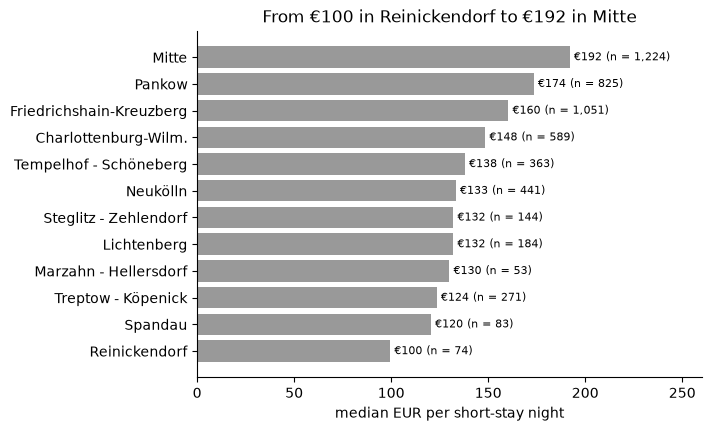

In [48]:
by_district = short_stay_listings.groupby("district")["price"].agg(n="size", median="median").sort_values("median")
fig, ax = plt.subplots(figsize=(7, 4.2), layout="constrained")
ax.barh(by_district.index, by_district["median"], color="0.6")
ax.bar_label(ax.containers[0], labels=[f"€{m:.0f} (n = {n:,})" for n, m in zip(by_district["n"], by_district["median"])],
             padding=3, fontsize=8)
ax.set(xlabel="median EUR per short-stay night", xlim=(0, 260),
       title=f"From €{by_district['median'].min():.0f} in Reinickendorf to €{by_district['median'].max():.0f} in Mitte")
plt.show()

### Step 3 · Median price per guest within entire homes

**Why this step?** Why restrict the comparison to entire homes before reading the effect of an additional guest?

Finally: how much more does a night cost per additional guest? Next we take the median price per number of guests for entire homes only (so that the room type does not mix in) and keep sizes with at least 30 listings. `query("n >= 30")` filters rows with a condition written as text.

**Predict.** Within entire homes, will the median price rise with every additional guest?

In [49]:
entire = short_stay_listings[short_stay_listings["room_type"] == "Entire home/apt"]
by_guests = entire.groupby("accommodates")["price"].agg(n="size", median="median").query("n >= 30")
print(by_guests.T.round(0))
print("Spearman (entire homes):", round(stats.spearmanr(entire["accommodates"], entire["price"]).statistic, 3))

accommodates     1       2      3      4      5      6      7      8      9   \
n              67.0  1158.0  437.0  900.0  280.0  418.0   91.0  137.0   47.0   
median        111.0   145.0  164.0  190.0  220.0  255.0  270.0  314.0  280.0   

accommodates     10     12  
n              60.0   30.0  
median        345.0  416.0  
Spearman (entire homes): 0.584


### Answer for the analyst

A short-stay night costs €157.50 at the median, with one listing in ten below €77 and one in ten above €334. Entire homes cost clearly more than private rooms. The district medians range from about €100 in Reinickendorf to €192 in Mitte, but the outer districts rest on few listings, and districts differ in their room-type mix. Within entire homes, the median rises with the number of guests, from €111 for one guest to €416 for twelve, with small dips where few listings are. Whether the district gaps survive once room type and size are held fixed is the question of block 2.

## Check your understanding

Vote alone first, discuss with your neighbour, then vote again.

1. Which statement about the variable types of the listings is correct?
   - A) `id` is stored as `int64`, so its mean is a meaningful summary.
   - B) `accommodates` is a count, so the share of listings for two guests is a sensible summary.
   - C) `room_type` is ordinal, because entire homes cost more than private rooms.
   - D) `last_review` is continuous, so its standard deviation is the best summary.
2. The mean short-stay price (€195.6) is well above the median (€157.5). What does this tell you?
   - A) Most listings cost more than €195.6.
   - B) The price column contains missing values.
   - C) The distribution has a long right tail that pulls the mean up.
   - D) The distribution is symmetric with two peaks.
3. A bar chart of median prices starts its axis at €100. Why is it misleading, when a line chart need not start at zero?
   - A) Readers compare bar lengths, and a cut axis makes the ratios between bars look larger than they are.
   - B) Every axis must start at zero, so the line chart is just as misleading.
   - C) Readers cannot see a tick label at €100.
   - D) Prices must always be shown on a log scale.
4. Dropping the five most expensive of the 5,302 listings moves Pearson's r between guests and price from 0.398 to 0.578. Why would Spearman's ρ (0.643 on all listings) hardly react to the same five listings?
   - A) Spearman's ρ removes outliers before it is computed.
   - B) Spearman's ρ is always larger than Pearson's r.
   - C) The five listings have no value for the number of guests.
   - D) On ranks, the most expensive listing is just the highest rank, however extreme its price.
5. Pooled, Friedrichshain-Kreuzberg is about €15 more expensive than Charlottenburg-Wilmersdorf; within each type of stay the gap is only a few euros. What created most of the pooled gap?
   - A) Friedrichshain-Kreuzberg lies closer to the centre.
   - B) Charlottenburg-Wilmersdorf has a larger share of medium-term listings, whose price field is low.
   - C) Chance: the two districts have too few listings.
   - D) Simpson's paradox: the order reverses within each type of stay.


## Exercises

Work in pairs; one of you types, the other directs. The lecturer chooses which exercises to set; there are more than fit into the time in class. The setup cells above must have run, so that `listings` and `short_stay_listings` exist.

### 1.1 · Mean of means

*Predict*

> Is the average of the district average prices equal to the average price of all listings?

*Source:* [Weighted arithmetic mean, Wikipedia](https://en.wikipedia.org/wiki/Weighted_arithmetic_mean)

*Your answer:*

### 1.2 · Fix the ugliest chart

*Paper*

> A bar chart with a truncated axis and a pie chart with twelve slices: redraw them.

*Source:* original exercise for this course; background: [Misleading graph, Wikipedia](https://en.wikipedia.org/wiki/Misleading_graph)

The starter cell draws the two charts to redraw (on paper first).

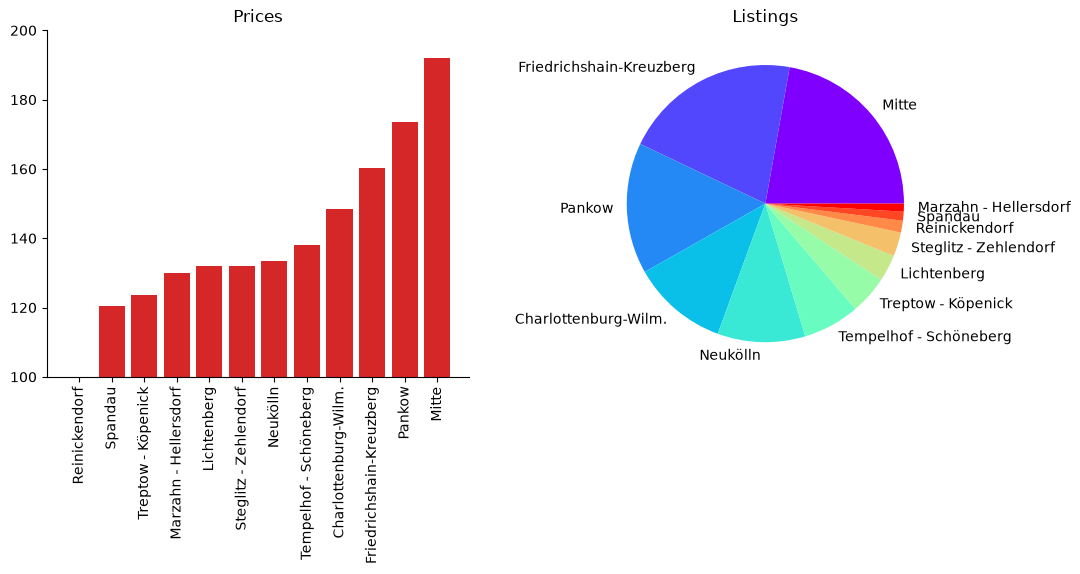

In [50]:
by_district_bad = short_stay_listings.groupby("district")["price"].median().sort_values()
fig, (left, right) = plt.subplots(1, 2, figsize=(12, 4.5))
left.bar(by_district_bad.index, by_district_bad, color="tab:red")
left.set_ylim(100, 200)
left.tick_params(axis="x", rotation=90)
left.set_title("Prices")
listings["district"].value_counts().plot.pie(ax=right, cmap="rainbow", ylabel="")
right.set_title("Listings")
plt.show()

*Your answer:*

### 1.3 · Build Simpson's paradox yourself

*Paper*

> Invent eight listings where district A is cheaper than B for every room type but more expensive overall.

*Source:* [Simpson's paradox, Wikipedia](https://en.wikipedia.org/wiki/Simpson%27s_paradox)

*Your answer:*

### 1.4 · Correlation zero, perfect relationship

*Code*

> Correlate x with x² for x = −3, …, 3.

*Source:* [Correlation, Wikipedia (uncorrelated is not independent)](https://en.wikipedia.org/wiki/Correlation)

### 1.5 · How full is the calendar?

*Code*

> Describe `availability_365` (free nights in the next 365 days) for each room type. Choose a chart that fits the type of the variable; report the share of listings with 0 and with 365 free nights, the median and the IQR; and explain in two sentences why the mean is a poor summary of this variable.

*Source:* original exercise for this course (Inside Airbnb Berlin case study)

### 1.6 · Does the price fall with the distance to the centre?

*Code*

> For the short-stay listings, draw the scatter plot of the price (log scale) against `km_to_centre`, compute Pearson's r on the log price and Spearman's ρ on the price, and repeat both within entire homes and within private rooms. Could room type be a confounder of this relationship? Name one other variable that could be.

*Source:* original exercise for this course (Inside Airbnb Berlin case study)

The starter cell adds `km_to_centre`, the straight-line distance in kilometres to Alexanderplatz.

In [51]:
short_stay_listings["km_to_centre"] = 111.2 * np.hypot(short_stay_listings["latitude"] - 52.5219,
                                         (short_stay_listings["longitude"] - 13.4132) * np.cos(np.radians(52.52)))

### 1.7 · Classify the variables

*Paper*

> Classify `room_type`, `accommodates`, `review_scores_rating` and `last_review` by variable type, and name one sensible summary and one fitting chart for each.

*Source:* original exercise for this course (Inside Airbnb Berlin case study)

*Your answer:*

### 1.8 · Reorder the percentile plot

*Parsons*

> The lines below draw the 10th, 50th and 90th percentile of the price per number of guests, for sizes with at least 30 listings. Put them in a working order and indent the one line that belongs inside the loop.
>
> ```python
> ax.plot(pct.index, pct[q], label=f"{q:.0%} percentile")
> keep_sizes = sizes[sizes >= 30].index
> ax.legend(frameon=False)
> fig, ax = plt.subplots(figsize=(7, 3.5))
> pct = short_stay_listings[short_stay_listings["accommodates"].isin(keep_sizes)].groupby("accommodates")["price"].quantile([0.1, 0.5, 0.9]).unstack()
> sizes = short_stay_listings["accommodates"].value_counts()
> for q in [0.1, 0.5, 0.9]:
> plt.show()
> ```

*Source:* original exercise for this course, after the section *Binned percentiles*

*Your answer:*

### 1.9 · The typical night

*Find the bug*

> This cell runs, but the sentence it prints is wrong. Find the two problems and write the corrected first line.
>
> ```python
> typical_night = listings["price"].mean()
> print(f"A typical short-stay night in Berlin costs €{typical_night:.0f}")
> ```

*Source:* original exercise for this course (Inside Airbnb Berlin case study)

*Your answer:*

## Debrief

- **Compare** two redrawn charts from 1.2 and two descriptions of the calendar from 1.5. Which redrawn chart answers a question in its title? Which description gives the shares at 0 and 365?
- **Typical mistakes:** a mean reported for a variable with spikes at 0 and 365; a correlation read as an effect of distance ("moving a flat closer to the centre raises its price"); a bar chart that still does not start at zero; a Simpson example in 1.3 where the room-type mix is the same in both districts (then no paradox can arise).
- **Bridge to block 2:** we have seen differences (entire homes against private rooms, Mitte against Neukölln) and relationships. Block 2 asks which of them are larger than chance, how large they are, and how to tell a reader.

## Further reading

- Wilke, C. O. (2019). *Fundamentals of Data Visualization*. O'Reilly. <https://clauswilke.com/dataviz/>
- Healy, K. (2018). *Data Visualization: A Practical Introduction*, chapter 1 "Look at data". <https://socviz.co/lookatdata.html>
- Downey, A. B. (2025). *Think Stats* (3rd ed.), chapters 1–4 and 7. <https://allendowney.github.io/ThinkStats/>
- Poldrack, R. A. (2023). *Statistical Thinking for the 21st Century*, chapter 4 "Summarizing data". <https://statsthinking21.github.io/statsthinking21-core-site/>
- Waskom, M. L. (2021). seaborn: statistical data visualization. *Journal of Open Source Software*, 6(60), 3021. Tutorials: <https://seaborn.pydata.org/tutorial.html>
- Matplotlib development team. *Quick start guide* and *Choosing Colormaps*. <https://matplotlib.org/stable/users/explain/quick_start.html>
- Plotly. *Plotly Express* and *Styling Plotly Express figures*. <https://plotly.com/python/plotly-express/>
- SciPy developers. *Pearson's correlation* and *Spearman correlation coefficient* tutorials. <https://docs.scipy.org/doc/scipy/tutorial/stats/hypothesis_tests.html>
- Cleveland, W. S., & McGill, R. (1984). Graphical perception. *Journal of the American Statistical Association*, 79(387), 531–554. <https://doi.org/10.1080/01621459.1984.10478080>
- Bickel, P. J., Hammel, E. A., & O'Connell, J. W. (1975). Sex bias in graduate admissions: Data from Berkeley. *Science*, 187(4175), 398–404. <https://doi.org/10.1126/science.187.4175.398>
- Charig, C. R., Webb, D. R., Payne, S. R., & Wickham, J. E. (1986). Comparison of treatment of renal calculi by open surgery, percutaneous nephrolithotomy, and extracorporeal shockwave lithotripsy. *BMJ*, 292(6524), 879–882. <https://doi.org/10.1136/bmj.292.6524.879>
- Matejka, J., & Fitzmaurice, G. (2017). Same stats, different graphs. *Proceedings of CHI 2017*. <https://doi.org/10.1145/3025453.3025912>
- National Eye Institute. *Color Blindness*. <https://www.nei.nih.gov/learn-about-eye-health/eye-conditions-and-diseases/color-blindness>
- Inside Airbnb. *Data assumptions*. <https://insideairbnb.com/data-assumptions/>
- Extras of this block: [extras/01](extras/01-exploratory-data-analysis.ipynb) to [extras/12](extras/12-spearman-correlation-test.ipynb); provenance in [extras/README.md](extras/README.md).

*Course team · Licence: CC BY 4.0. Sections marked "Adapted from" contain text and code from the seaborn (BSD-3-Clause), matplotlib (Matplotlib licence), Plotly (MIT), SciPy (BSD-3-Clause) and Microsoft Data Science for Beginners (MIT) documentation, edited and applied to the Berlin listings.*